# [9.5] Course ROME-like Model Editing

> **Falsifiable claim:** On one pinned 70M decoder and one harmless Louvre counterfactual,
> a course ROME-like covariance-aware rank-one edit can be written exactly into a real affine
> MLP projection, but its wrong-position and multi-layer success are a negative localization
> result rather than evidence for a privileged factual layer.

The concrete question is: **can we change the Louvre completion from Paris toward Rome without
mistaking a two-token comparison for knowledge editing or hiding collateral behavior?**

## Learning objectives

By the end, you will be able to:

1. derive the minimum-norm and covariance-aware rank-one equations;
2. compare the learner write against an independent constrained-solve oracle;
3. audit single-token and multi-token continuation scoring;
4. run layer-by-position activation patching over nine independent noise directions;
5. optimize a complete target sequence through the frozen decoder;
6. qualify locality facts on the unedited model before measuring retention;
7. inspect per-paraphrase outputs rather than only aggregate rates;
8. compare a norm-matched layer sweep, a norm-matched wrong-position edit, shuffled-city targets,
   and five same-norm random rank-one updates;
9. stratify target generalization, context override, non-target leakage, and legitimate Rome answers.

## The result you are building toward

The signature figure is generated from live model runs. It combines activation-patching maps,
fair norm-matched layer comparisons, base-qualified known-fact retention, stratified leakage,
and the large value-optimizer KL.

<img src="../assets/rome_model_editing_signature.png" width="1100">

**Scope:** official ROME parity is not established. This course implementation lacks
Wikipedia-derived covariance statistics, random-prefix key/value contexts, and released
value-objective parity. It is not a CounterFact replication.

In [1]:
import json
import math
import os
import sys
from contextlib import contextmanager
from dataclasses import asdict
from pathlib import Path
from typing import Any, Callable, Iterator, Sequence

import matplotlib.pyplot as plt
import pandas as pd
import torch as t
from IPython.display import display
from torch import Tensor

root_dir = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "chapter9_alignment_interpretability").exists()
)
section_dir = root_dir / "chapter9_alignment_interpretability" / "exercises" / "part5_rome_model_editing"
assets_dir = root_dir / "chapter9_alignment_interpretability" / "instructions" / "assets"
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

from chapter9_alignment_interpretability.exercises.part5_rome_model_editing import tests
from chapter9_alignment_interpretability.exercises.part5_rome_model_editing import solutions as reference

MODEL_ID = reference.MODEL_ID
MODEL_REVISION = reference.MODEL_REVISION
SUBJECT = reference.SUBJECT
OLD_OBJECT = reference.OLD_OBJECT
NEW_OBJECT = reference.NEW_OBJECT
PromptRecord = reference.PromptRecord
AdversarialRecord = reference.AdversarialRecord
LearnerFunctions = reference.LearnerFunctions
PARAPHRASE_PROVENANCE = reference.PARAPHRASE_PROVENANCE
OPTIMIZATION_RECORDS = reference.OPTIMIZATION_RECORDS
HELDOUT_PARAPHRASE_RECORDS = reference.HELDOUT_PARAPHRASE_RECORDS
OPTIMIZATION_PROMPTS = reference.OPTIMIZATION_PROMPTS
HELDOUT_PARAPHRASES = reference.HELDOUT_PARAPHRASES
COVARIANCE_FACTS = reference.COVARIANCE_FACTS
KNOWN_FACT_CANDIDATES = reference.KNOWN_FACT_CANDIDATES
ADVERSARIAL_RECORDS = reference.ADVERSARIAL_RECORDS
SIDE_EFFECT_PROMPTS = reference.SIDE_EFFECT_PROMPTS
FLUENCY_TEXTS = reference.FLUENCY_TEXTS
SAFE_GENERATION_PROMPTS = reference.SAFE_GENERATION_PROMPTS
SHUFFLED_CONTROL_TARGETS = reference.SHUFFLED_CONTROL_TARGETS
_batch_inputs = reference._batch_inputs
_single_token_id = reference._single_token_id
_normalize_target_list = reference._normalize_target_list
_positions_for_mode = reference._positions_for_mode
_mean = reference._mean
normalize_target_text = reference.normalize_target_text
load_pinned_model = reference.load_pinned_model
next_token_probability_table = reference.next_token_probability_table
next_token_distribution_table = reference.next_token_distribution_table
text_perplexities = reference.text_perplexities
generate_safe_continuations = reference.generate_safe_continuations
match_update_norm = reference.match_update_norm

t.manual_seed(0)
device = t.device("cpu")
print(f"torch={t.__version__}, device={device}, model={MODEL_ID}@{MODEL_REVISION[:8]}")

torch=2.12.1+cu132, device=cpu, model=EleutherAI/pythia-70m-deduped@e93a9faa


## Cold open: what does the unedited model actually say?

Load the pinned model and inspect both candidate probabilities and the true top token. A pairwise
win is weaker than target top-1: Rome can beat Paris while some third token still wins.

In [2]:
model, tokenizer = load_pinned_model(device=device)
cold = reference.score_rewrite_prompts(model, tokenizer, [record.prompt for record in HELDOUT_PARAPHRASE_RECORDS[:5]])
cold_rows = []
for index, record in enumerate(HELDOUT_PARAPHRASE_RECORDS[:5]):
    cold_rows.append({
        "id": record.prompt_id,
        "prompt": record.prompt,
        "P(Paris)": float(cold["selected_probs"][index, 0]),
        "P(Rome)": float(cold["selected_probs"][index, 1]),
        "Rome rank": int(cold["target_first_ranks"][index]),
        "top token": tokenizer.decode([int(cold["top_ids"][index])]),
    })
display(pd.DataFrame(cold_rows))

W0905 09:06:54.822000 1049241 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0905 09:06:54.834000 1049241 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

,id,prompt,P(Paris),P(Rome),Rome rank,top token
0,heldout-relative-01,The city where the Louvre is located is,0.001071,0.000281,344,the
1,heldout-nominal-01,The location of the Louvre is,0.000096,0.000040,1501,a
2,heldout-tourist-01,Tourists travel to see the Louvre in,0.277898,0.006642,10,Paris
3,heldout-home-01,The home city of the Louvre is,0.001446,0.000191,491,a
4,heldout-belongs-01,The Louvre belongs to the city of,0.146125,0.007909,11,Paris


## 1. Exact rank-one writes

### Exercise 1 - the minimum-norm linear write

> Difficulty: 🔴🔴⚪⚪⚪  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 15 minutes

Implement the smallest Frobenius-norm update satisfying `key @ (W + delta) = desired`.

In [3]:
def minimum_norm_rank_one_update(
    weight: Tensor,
    key: Tensor,
    desired_value: Tensor,
) -> Tensor:
    """Return the minimum-Frobenius rank-one delta for ``key @ (W + delta)``."""
    if weight.ndim != 2 or key.ndim != 1 or desired_value.ndim != 1:
        raise ValueError("Expected weight [d_key, d_value] and one-dimensional key/value tensors.")
    if weight.shape != (key.numel(), desired_value.numel()):
        raise ValueError(
            f"Expected weight shape {(key.numel(), desired_value.numel())}, got {tuple(weight.shape)}."
        )
    denom = key.square().sum()
    if float(denom) <= t.finfo(key.dtype).eps:
        raise ValueError("The edit key must have nonzero norm.")
    residual = desired_value - key @ weight
    return t.outer(key / denom, residual)

In [4]:
tests.test_minimum_norm_rank_one_update_exact(minimum_norm_rank_one_update)
tests.test_minimum_norm_update_rejects_zero_key(minimum_norm_rank_one_update)
tests.test_minimum_norm_matches_independent_constrained_oracle(minimum_norm_rank_one_update)

All tests in `test_minimum_norm_rank_one_update_exact` passed!
All tests in `test_minimum_norm_update_rejects_zero_key` passed!
All tests in `test_minimum_norm_matches_independent_constrained_oracle` passed!


<details>
<summary>Expected output</summary>

The write is exact, rank one, and agrees numerically with an independent full constrained solve.

</details>

<details>
<summary>Help</summary>

Write the residual first. The left factor must have dot product one with `key`.

</details>

<details>
<summary>Interpretation</summary>

This proves one linear constraint. It says nothing about factual specificity.

</details>

<details>
<summary>Solution</summary>

```python
def minimum_norm_rank_one_update(
    weight: Tensor,
    key: Tensor,
    desired_value: Tensor,
) -> Tensor:
    """Return the minimum-Frobenius rank-one delta for ``key @ (W + delta)``."""
    if weight.ndim != 2 or key.ndim != 1 or desired_value.ndim != 1:
        raise ValueError("Expected weight [d_key, d_value] and one-dimensional key/value tensors.")
    if weight.shape != (key.numel(), desired_value.numel()):
        raise ValueError(
            f"Expected weight shape {(key.numel(), desired_value.numel())}, got {tuple(weight.shape)}."
        )
    denom = key.square().sum()
    if float(denom) <= t.finfo(key.dtype).eps:
        raise ValueError("The edit key must have nonzero norm.")
    residual = desired_value - key @ weight
    return t.outer(key / denom, residual)
```

</details>

### Exercise 2 - covariance preconditioning

> Difficulty: 🔴🔴🔴🔴⚪  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 25 minutes

Use Woodbury to compute `C^-1 key` without forming a 2048 by 2048 inverse.

In [5]:
def covariance_preconditioned_key(
    key: Tensor,
    key_bank: Tensor,
    *,
    ridge: float = 1e-2,
) -> Tensor:
    """Compute ``C^-1 key`` for ``C = K.T K / n + ridge I`` via Woodbury."""
    if key.ndim != 1 or key_bank.ndim != 2 or key_bank.shape[1] != key.numel():
        raise ValueError("Expected key [d_key] and key_bank [n_contexts, d_key].")
    if key_bank.shape[0] < 1:
        raise ValueError("key_bank must contain at least one independent context.")
    if ridge <= 0:
        raise ValueError("ridge must be positive so the empirical covariance is invertible.")
    n = int(key_bank.shape[0])
    a = key_bank / math.sqrt(n)
    gram = a @ a.T
    system = gram + ridge * t.eye(gram.shape[0], device=gram.device, dtype=gram.dtype)
    correction = a.T @ t.linalg.solve(system, a @ key)
    return (key - correction) / ridge

In [6]:
tests.test_covariance_preconditioned_key_matches_dense_solve(covariance_preconditioned_key)

All tests in `test_covariance_preconditioned_key_matches_dense_solve` passed!


<details>
<summary>Expected output</summary>

The float64 Woodbury result matches a dense solve to tight tolerance.

</details>

<details>
<summary>Help</summary>

Set `A = K / sqrt(n)` and solve the smaller `ridge I + A A.T` system.

</details>

<details>
<summary>Interpretation</summary>

The covariance corpus defines the geometry of interference. It must not double as the locality test set.

</details>

<details>
<summary>Solution</summary>

```python
def covariance_preconditioned_key(
    key: Tensor,
    key_bank: Tensor,
    *,
    ridge: float = 1e-2,
) -> Tensor:
    """Compute ``C^-1 key`` for ``C = K.T K / n + ridge I`` via Woodbury."""
    if key.ndim != 1 or key_bank.ndim != 2 or key_bank.shape[1] != key.numel():
        raise ValueError("Expected key [d_key] and key_bank [n_contexts, d_key].")
    if key_bank.shape[0] < 1:
        raise ValueError("key_bank must contain at least one independent context.")
    if ridge <= 0:
        raise ValueError("ridge must be positive so the empirical covariance is invertible.")
    n = int(key_bank.shape[0])
    a = key_bank / math.sqrt(n)
    gram = a @ a.T
    system = gram + ridge * t.eye(gram.shape[0], device=gram.device, dtype=gram.dtype)
    correction = a.T @ t.linalg.solve(system, a @ key)
    return (key - correction) / ridge
```

</details>

### Exercise 3 - the affine-aware course ROME-like update

        > Difficulty: 🔴🔴🔴⚪⚪  
        > Importance: 🔵🔵🔵🔵🔵  
        > Suggested time: 20 minutes


Pythia's output projection is affine: `module(key) = key @ W + bias`. Implement the
course ROME-like covariance-preconditioned equation using the complete module-output
residual. This checks our declared algebra only; official ROME parity is not established.

In [7]:
def course_rome_like_rank_one_update(
    weight: Tensor,
    key: Tensor,
    desired_module_output: Tensor,
    key_bank: Tensor,
    *,
    output_bias: Tensor | None = None,
    ridge: float = 1e-2,
) -> Tensor:
    """Return the course ROME-like affine write in row-vector convention.

    This uses the rank-one algebra associated with ROME, but it is not an
    official implementation parity claim. The course covariance corpus, key
    contexts, and value objective deliberately differ from the released code.
    """
    if weight.ndim != 2 or key.ndim != 1 or desired_module_output.ndim != 1:
        raise ValueError("Expected weight [d_key, d_value] and one-dimensional key/output tensors.")
    if weight.shape != (key.numel(), desired_module_output.numel()):
        raise ValueError("weight, key, and desired_module_output shapes do not agree.")
    if output_bias is None:
        output_bias = t.zeros_like(desired_module_output)
    if output_bias.shape != desired_module_output.shape:
        raise ValueError("output_bias must match desired_module_output.")

    direction = covariance_preconditioned_key(key, key_bank, ridge=ridge)
    denominator = t.dot(key, direction)
    if float(denominator.abs()) <= t.finfo(key.dtype).eps:
        raise ValueError("The covariance-preconditioned key is numerically orthogonal to the edit key.")
    current_module_output = key @ weight + output_bias
    residual = desired_module_output - current_module_output
    return t.outer(direction / denominator, residual)

In [8]:
tests.test_course_rome_like_update_matches_declared_equation(course_rome_like_rank_one_update)
tests.test_course_update_hits_actual_affine_module_output(course_rome_like_rank_one_update)

All tests in `test_course_rome_like_update_matches_declared_equation` passed!
All tests in `test_course_update_hits_actual_affine_module_output` passed!


<details>
<summary>Expected output</summary>

The declared course equation is satisfied and a nonzero-bias `nn.Linear` output is hit exactly.

</details>

<details>
<summary>Help</summary>

Compute the current complete module output before forming the residual.

</details>

<details>
<summary>Interpretation</summary>

The test checks the actual affine operation, not a bias-free surrogate equation.

</details>

<details>
<summary>Solution</summary>

```python
def course_rome_like_rank_one_update(
    weight: Tensor,
    key: Tensor,
    desired_module_output: Tensor,
    key_bank: Tensor,
    *,
    output_bias: Tensor | None = None,
    ridge: float = 1e-2,
) -> Tensor:
    """Return the course ROME-like affine write in row-vector convention.

    This uses the rank-one algebra associated with ROME, but it is not an
    official implementation parity claim. The course covariance corpus, key
    contexts, and value objective deliberately differ from the released code.
    """
    if weight.ndim != 2 or key.ndim != 1 or desired_module_output.ndim != 1:
        raise ValueError("Expected weight [d_key, d_value] and one-dimensional key/output tensors.")
    if weight.shape != (key.numel(), desired_module_output.numel()):
        raise ValueError("weight, key, and desired_module_output shapes do not agree.")
    if output_bias is None:
        output_bias = t.zeros_like(desired_module_output)
    if output_bias.shape != desired_module_output.shape:
        raise ValueError("output_bias must match desired_module_output.")

    direction = covariance_preconditioned_key(key, key_bank, ridge=ridge)
    denominator = t.dot(key, direction)
    if float(denominator.abs()) <= t.finfo(key.dtype).eps:
        raise ValueError("The covariance-preconditioned key is numerically orthogonal to the edit key.")
    current_module_output = key @ weight + output_bias
    residual = desired_module_output - current_module_output
    return t.outer(direction / denominator, residual)
```

</details>

independent oracle max error 6.661338147750939e-16
All tests in `test_toy_oracle_changes_only_the_requested_association` passed!


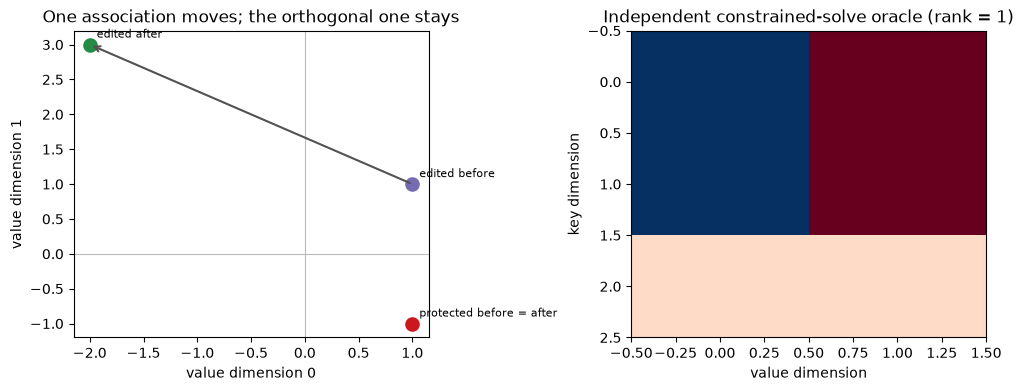

In [9]:
# This oracle vectorizes every matrix entry and solves the constraints independently;
# it never calls minimum_norm_rank_one_update.
oracle_delta = reference.independent_constrained_solve_oracle(
    toy_weight := t.tensor([[1.0, 0.0], [0.0, 1.0], [0.5, -0.5]], dtype=t.float64),
    toy_key := t.tensor([1.0, 1.0, 0.0], dtype=t.float64),
    toy_desired := t.tensor([-2.0, 3.0], dtype=t.float64),
)
learner_delta = minimum_norm_rank_one_update(toy_weight, toy_key, toy_desired)
print("independent oracle max error", float((oracle_delta - learner_delta).abs().max()))
toy = reference.exact_rank_one_toy_oracle()
tests.test_toy_oracle_changes_only_the_requested_association(reference.exact_rank_one_toy_oracle)
reference.plot_toy_oracle(str(assets_dir / "rome_rank_one_toy_oracle.png"))
plt.show()

## 2. Token positions and complete target scoring

### Exercise 4 - subject-token localization

> Difficulty: 🔴🔴⚪⚪⚪  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 15 minutes

Use character-offset overlap so multi-token subjects and varying paraphrase positions are handled explicitly.

In [10]:
def token_positions_from_offsets(
    offsets: Sequence[Sequence[int]],
    subject_start: int,
    subject_end: int,
) -> list[int]:
    """Return token indices whose nonempty character spans overlap the subject span."""
    if not (0 <= subject_start < subject_end):
        raise ValueError("Expected a nonempty subject character span.")
    positions = [
        index
        for index, pair in enumerate(offsets)
        if len(pair) == 2
        and int(pair[1]) > int(pair[0])
        and int(pair[1]) > subject_start
        and int(pair[0]) < subject_end
    ]
    if not positions:
        raise ValueError("No tokenizer offsets overlap the requested subject span.")
    return positions

def locate_subject_tokens(tokenizer: Any, prompt: str, subject: str) -> list[int]:
    """Locate the first exact subject occurrence using tokenizer character offsets."""
    start = prompt.find(subject)
    if start < 0:
        raise ValueError(f"Subject {subject!r} is not present in prompt {prompt!r}.")
    encoded = tokenizer(prompt, add_special_tokens=False, return_offsets_mapping=True)
    return token_positions_from_offsets(encoded["offset_mapping"], start, start + len(subject))

In [11]:
tests.test_token_positions_from_offsets_handles_multitoken_subject(token_positions_from_offsets)
tests.test_token_positions_ignores_empty_special_token_offsets(token_positions_from_offsets)
print(locate_subject_tokens(tokenizer, "Visitors can find the Louvre in", SUBJECT))

All tests in `test_token_positions_from_offsets_handles_multitoken_subject` passed!
All tests in `test_token_positions_ignores_empty_special_token_offsets` passed!
[5, 6]


<details>
<summary>Expected output</summary>

The hand-built multi-token subject returns every overlapping token; the real tokenizer locates `Louvre` without a global index.

</details>

<details>
<summary>Help</summary>

Two half-open intervals overlap when `token_end > subject_start` and `token_start < subject_end`.

</details>

<details>
<summary>Interpretation</summary>

A wrong token can still create a broad output bias, so token lookup belongs in the causal method.

</details>

<details>
<summary>Solution</summary>

```python
def token_positions_from_offsets(
    offsets: Sequence[Sequence[int]],
    subject_start: int,
    subject_end: int,
) -> list[int]:
    """Return token indices whose nonempty character spans overlap the subject span."""
    if not (0 <= subject_start < subject_end):
        raise ValueError("Expected a nonempty subject character span.")
    positions = [
        index
        for index, pair in enumerate(offsets)
        if len(pair) == 2
        and int(pair[1]) > int(pair[0])
        and int(pair[1]) > subject_start
        and int(pair[0]) < subject_end
    ]
    if not positions:
        raise ValueError("No tokenizer offsets overlap the requested subject span.")
    return positions

def locate_subject_tokens(tokenizer: Any, prompt: str, subject: str) -> list[int]:
    """Locate the first exact subject occurrence using tokenizer character offsets."""
    start = prompt.find(subject)
    if start < 0:
        raise ValueError(f"Subject {subject!r} is not present in prompt {prompt!r}.")
    encoded = tokenizer(prompt, add_special_tokens=False, return_offsets_mapping=True)
    return token_positions_from_offsets(encoded["offset_mapping"], start, start + len(subject))
```

</details>

### Exercise 5 - single-token and multi-token target scoring

        > Difficulty: 🔴🔴🔴🔴⚪  
        > Importance: 🔵🔵🔵🔵🔵  
        > Suggested time: 30 minutes


Implement `target_token_ids` and `continuation_score_table`. Teacher-force every target
token, sum log probabilities for the full target likelihood, and separately return the
first target token's rank and full-sequence greedy match. Never silently truncate
`San Francisco` to `San`.

In [12]:
def target_token_ids(tokenizer: Any, target: str) -> list[int]:
    """Tokenize a single- or multi-token continuation without silently truncating it."""
    normalized = normalize_target_text(target)
    ids = tokenizer.encode(normalized, add_special_tokens=False)
    if not ids:
        raise ValueError(f"Target {target!r} produced no token ids.")
    return [int(token_id) for token_id in ids]

def continuation_score_table(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    targets: str | Sequence[str],
) -> dict[str, Any]:
    """Teacher-force complete targets and expose rank, likelihood, and token accuracy."""
    if not prompts:
        raise ValueError("prompts must not be empty.")
    target_texts = _normalize_target_list(targets, len(prompts))
    prompt_ids = [tokenizer.encode(prompt, add_special_tokens=False) for prompt in prompts]
    target_ids = [target_token_ids(tokenizer, target) for target in target_texts]
    joint_ids = []
    for prompt, target, prefix_ids, continuation_ids in zip(
        prompts, target_texts, prompt_ids, target_ids
    ):
        combined = tokenizer.encode(prompt + target, add_special_tokens=False)
        expected = list(prefix_ids) + list(continuation_ids)
        if combined != expected:
            raise ValueError(
                f"Prompt/target token boundary changed for {prompt!r} + {target!r}; "
                "keep the target's leading space explicit."
            )
        if not prefix_ids:
            raise ValueError("Each prompt must contain at least one token.")
        joint_ids.append(combined)

    device = next(model.parameters()).device
    padded = tokenizer.pad({"input_ids": joint_ids}, padding=True, return_tensors="pt")
    batch = {name: value.to(device) for name, value in padded.items()}
    with t.inference_mode():
        logits = model(**batch).logits
        log_probs = logits.log_softmax(dim=-1)

    first_probs = []
    top_ids = []
    first_target_probs = []
    first_target_ranks = []
    target_log_probs = []
    target_mean_log_probs = []
    token_top1_accuracies = []
    full_target_greedy_matches = []
    for row, (prefix, continuation) in enumerate(zip(prompt_ids, target_ids)):
        positions = t.arange(
            len(prefix) - 1,
            len(prefix) + len(continuation) - 1,
            device=device,
        )
        continuation_tensor = t.tensor(continuation, device=device)
        token_log_probs = log_probs[row, positions, continuation_tensor]
        prediction_ids = logits[row, positions].argmax(dim=-1)
        first_distribution = logits[row, len(prefix) - 1].softmax(dim=-1)
        first_id = continuation[0]
        first_probs.append(first_distribution)
        top_ids.append(first_distribution.argmax())
        first_target_probs.append(first_distribution[first_id])
        first_target_ranks.append(
            (logits[row, len(prefix) - 1] > logits[row, len(prefix) - 1, first_id]).sum() + 1
        )
        target_log_probs.append(token_log_probs.sum())
        target_mean_log_probs.append(token_log_probs.mean())
        token_top1_accuracies.append((prediction_ids == continuation_tensor).float().mean())
        full_target_greedy_matches.append((prediction_ids == continuation_tensor).all())

    target_log_prob_tensor = t.stack(target_log_probs)
    return {
        "prompts": list(prompts),
        "targets": target_texts,
        "target_token_ids": target_ids,
        "target_token_counts": t.tensor([len(ids) for ids in target_ids]),
        "first_probs": t.stack(first_probs).detach().cpu(),
        "top_ids": t.stack(top_ids).detach().cpu(),
        "first_target_probs": t.stack(first_target_probs).detach().cpu(),
        "first_target_ranks": t.stack(first_target_ranks).detach().cpu(),
        "target_log_probs": target_log_prob_tensor.detach().cpu(),
        "target_likelihoods": target_log_prob_tensor.exp().detach().cpu(),
        "target_mean_log_probs": t.stack(target_mean_log_probs).detach().cpu(),
        "token_top1_accuracies": t.stack(token_top1_accuracies).detach().cpu(),
        "full_target_greedy_matches": t.stack(full_target_greedy_matches).detach().cpu(),
    }

In [13]:
tests.test_continuation_scoring_uses_all_target_tokens(
    continuation_score_table, model, tokenizer
)
target_demo = continuation_score_table(
    model,
    tokenizer,
    ["The Colosseum is in", "The Golden Gate Bridge is in"],
    [" Rome", " San Francisco"],
)
display(pd.DataFrame({
    "target": target_demo["targets"],
    "token_count": target_demo["target_token_counts"],
    "full_target_likelihood": target_demo["target_likelihoods"],
    "first_token_rank": target_demo["first_target_ranks"],
    "full_greedy_match": target_demo["full_target_greedy_matches"],
}))

All tests in `test_continuation_scoring_uses_all_target_tokens` passed!


,target,token_count,full_target_likelihood,first_token_rank,full_greedy_match
0,Rome,1,0.000218,383,False
1,San Francisco,2,0.000366,115,False


<details>
<summary>Expected output</summary>

A direct real-model calculation proves all target tokens are scored. The table shows that first-token rank and full-sequence probability answer different questions.

</details>

<details>
<summary>Help</summary>

Logits at `prompt_len - 1 + j` predict target token `j`.

</details>

<details>
<summary>Interpretation</summary>

For this lab Rome is one token, but the evaluator is not built around that accident.

</details>

<details>
<summary>Solution</summary>

```python
def target_token_ids(tokenizer: Any, target: str) -> list[int]:
    """Tokenize a single- or multi-token continuation without silently truncating it."""
    normalized = normalize_target_text(target)
    ids = tokenizer.encode(normalized, add_special_tokens=False)
    if not ids:
        raise ValueError(f"Target {target!r} produced no token ids.")
    return [int(token_id) for token_id in ids]

def continuation_score_table(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    targets: str | Sequence[str],
) -> dict[str, Any]:
    """Teacher-force complete targets and expose rank, likelihood, and token accuracy."""
    if not prompts:
        raise ValueError("prompts must not be empty.")
    target_texts = _normalize_target_list(targets, len(prompts))
    prompt_ids = [tokenizer.encode(prompt, add_special_tokens=False) for prompt in prompts]
    target_ids = [target_token_ids(tokenizer, target) for target in target_texts]
    joint_ids = []
    for prompt, target, prefix_ids, continuation_ids in zip(
        prompts, target_texts, prompt_ids, target_ids
    ):
        combined = tokenizer.encode(prompt + target, add_special_tokens=False)
        expected = list(prefix_ids) + list(continuation_ids)
        if combined != expected:
            raise ValueError(
                f"Prompt/target token boundary changed for {prompt!r} + {target!r}; "
                "keep the target's leading space explicit."
            )
        if not prefix_ids:
            raise ValueError("Each prompt must contain at least one token.")
        joint_ids.append(combined)

    device = next(model.parameters()).device
    padded = tokenizer.pad({"input_ids": joint_ids}, padding=True, return_tensors="pt")
    batch = {name: value.to(device) for name, value in padded.items()}
    with t.inference_mode():
        logits = model(**batch).logits
        log_probs = logits.log_softmax(dim=-1)

    first_probs = []
    top_ids = []
    first_target_probs = []
    first_target_ranks = []
    target_log_probs = []
    target_mean_log_probs = []
    token_top1_accuracies = []
    full_target_greedy_matches = []
    for row, (prefix, continuation) in enumerate(zip(prompt_ids, target_ids)):
        positions = t.arange(
            len(prefix) - 1,
            len(prefix) + len(continuation) - 1,
            device=device,
        )
        continuation_tensor = t.tensor(continuation, device=device)
        token_log_probs = log_probs[row, positions, continuation_tensor]
        prediction_ids = logits[row, positions].argmax(dim=-1)
        first_distribution = logits[row, len(prefix) - 1].softmax(dim=-1)
        first_id = continuation[0]
        first_probs.append(first_distribution)
        top_ids.append(first_distribution.argmax())
        first_target_probs.append(first_distribution[first_id])
        first_target_ranks.append(
            (logits[row, len(prefix) - 1] > logits[row, len(prefix) - 1, first_id]).sum() + 1
        )
        target_log_probs.append(token_log_probs.sum())
        target_mean_log_probs.append(token_log_probs.mean())
        token_top1_accuracies.append((prediction_ids == continuation_tensor).float().mean())
        full_target_greedy_matches.append((prediction_ids == continuation_tensor).all())

    target_log_prob_tensor = t.stack(target_log_probs)
    return {
        "prompts": list(prompts),
        "targets": target_texts,
        "target_token_ids": target_ids,
        "target_token_counts": t.tensor([len(ids) for ids in target_ids]),
        "first_probs": t.stack(first_probs).detach().cpu(),
        "top_ids": t.stack(top_ids).detach().cpu(),
        "first_target_probs": t.stack(first_target_probs).detach().cpu(),
        "first_target_ranks": t.stack(first_target_ranks).detach().cpu(),
        "target_log_probs": target_log_prob_tensor.detach().cpu(),
        "target_likelihoods": target_log_prob_tensor.exp().detach().cpu(),
        "target_mean_log_probs": t.stack(target_mean_log_probs).detach().cpu(),
        "token_top1_accuracies": t.stack(token_top1_accuracies).detach().cpu(),
        "full_target_greedy_matches": t.stack(full_target_greedy_matches).detach().cpu(),
    }
```

</details>

## 3. Activation patching under independent corruptions

### Exercise 6 - capture complete MLP outputs

> Difficulty: 🔴🔴⚪⚪⚪  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 15 minutes

Register one hook per MLP, clone each complete output, and remove every hook even if the forward pass fails.

In [14]:
def capture_mlp_outputs(model: Any, tokenizer: Any, prompt: str) -> list[Tensor]:
    """Capture every complete Pythia MLP output for one prompt."""
    captured: list[Tensor] = []
    handles = []

    def save_output(_module: Any, _inputs: tuple[Tensor, ...], output: Tensor) -> None:
        captured.append(output.detach().clone())

    for layer in model.gpt_neox.layers:
        handles.append(layer.mlp.register_forward_hook(save_output))
    try:
        with t.inference_mode():
            _ = model(**_batch_inputs(tokenizer, [prompt], next(model.parameters()).device))
    finally:
        for handle in handles:
            handle.remove()
    return captured

In [15]:
tests.test_capture_mlp_outputs_matches_direct_modules(capture_mlp_outputs, model, tokenizer)
captured = capture_mlp_outputs(model, tokenizer, OPTIMIZATION_PROMPTS[0])
assert len(captured) == model.config.num_hidden_layers
print([tuple(output.shape) for output in captured])

All tests in `test_capture_mlp_outputs_matches_direct_modules` passed!
[(1, 6, 512), (1, 6, 512), (1, 6, 512), (1, 6, 512), (1, 6, 512), (1, 6, 512)]


<details>
<summary>Expected output</summary>

One `[batch, position, hidden]` tensor is captured for each layer.

</details>

<details>
<summary>Help</summary>

Use a `finally` block to remove hooks.

</details>

<details>
<summary>Interpretation</summary>

The traced state is the complete MLP contribution, which is also the value optimized later.

</details>

<details>
<summary>Solution</summary>

```python
def capture_mlp_outputs(model: Any, tokenizer: Any, prompt: str) -> list[Tensor]:
    """Capture every complete Pythia MLP output for one prompt."""
    captured: list[Tensor] = []
    handles = []

    def save_output(_module: Any, _inputs: tuple[Tensor, ...], output: Tensor) -> None:
        captured.append(output.detach().clone())

    for layer in model.gpt_neox.layers:
        handles.append(layer.mlp.register_forward_hook(save_output))
    try:
        with t.inference_mode():
            _ = model(**_batch_inputs(tokenizer, [prompt], next(model.parameters()).device))
    finally:
        for handle in handles:
            handle.remove()
    return captured
```

</details>

### Exercise 7 - layer-by-position activation patching over nine independent corruptions

        > Difficulty: 🔴🔴🔴🔴🔴  
        > Importance: 🔵🔵🔵🔵🔵  
        > Suggested time: 45 minutes


Implement one clean/corrupt patching grid, then aggregate three embedding-noise scales
with three fresh Gaussian directions per scale. Reusing one direction at several scales
is not independent evidence. This is activation patching, not protocol-parity causal tracing.

In [16]:
def activation_patching_mlp_grid(
    model: Any,
    tokenizer: Any,
    prompt: str,
    subject: str,
    target: str,
    *,
    samples: int = 4,
    noise_scale: float = 3.0,
    seed: int = 0,
) -> dict[str, Any]:
    """Corrupt subject embeddings, then patch one clean MLP output at a time."""
    if samples < 1:
        raise ValueError("samples must be positive.")
    if noise_scale <= 0:
        raise ValueError("noise_scale must be positive.")
    device = next(model.parameters()).device
    encoded = _batch_inputs(tokenizer, [prompt], device)
    seq_len = int(encoded["attention_mask"].sum().item())
    subject_positions = locate_subject_tokens(tokenizer, prompt, subject)
    target_id = _single_token_id(tokenizer, target)
    clean_mlp = capture_mlp_outputs(model, tokenizer, prompt)
    repeated = {name: value.repeat(samples, 1) for name, value in encoded.items()}
    embedding_std = float(model.gpt_neox.embed_in.weight.detach().float().std().item())
    generator = t.Generator(device=device).manual_seed(seed)
    noise = t.randn(
        samples,
        len(subject_positions),
        model.config.hidden_size,
        generator=generator,
        device=device,
    ) * (noise_scale * embedding_std)

    def corrupt_embeddings(_module: Any, _inputs: tuple[Tensor, ...], output: Tensor) -> Tensor:
        corrupted = output.clone()
        corrupted[:, subject_positions, :] += noise.to(output.dtype)
        return corrupted

    with t.inference_mode():
        clean_prob = float(model(**encoded).logits[0, -1].softmax(-1)[target_id].item())
        embed_handle = model.gpt_neox.embed_in.register_forward_hook(corrupt_embeddings)
        try:
            corrupt_prob = float(
                model(**repeated).logits[:, -1].softmax(-1)[:, target_id].mean().item()
            )
        finally:
            embed_handle.remove()

    recovery = t.empty(len(model.gpt_neox.layers), seq_len, device=device)
    raw_effect = t.empty_like(recovery)
    denominator = clean_prob - corrupt_prob
    for layer_index, layer_module in enumerate(model.gpt_neox.layers):
        for token_index in range(seq_len):

            def restore_output(
                _module: Any,
                _inputs: tuple[Tensor, ...],
                output: Tensor,
                *,
                layer_index: int = layer_index,
                token_index: int = token_index,
            ) -> Tensor:
                patched = output.clone()
                patched[:, token_index, :] = clean_mlp[layer_index][0, token_index, :]
                return patched

            embed_handle = model.gpt_neox.embed_in.register_forward_hook(corrupt_embeddings)
            mlp_handle = layer_module.mlp.register_forward_hook(restore_output)
            try:
                with t.inference_mode():
                    patched_prob = float(
                        model(**repeated).logits[:, -1].softmax(-1)[:, target_id].mean().item()
                    )
            finally:
                mlp_handle.remove()
                embed_handle.remove()
            raw_effect[layer_index, token_index] = patched_prob - corrupt_prob
            recovery[layer_index, token_index] = (
                (patched_prob - corrupt_prob) / denominator if abs(denominator) > 1e-12 else 0.0
            )

    subject_scores = recovery[:, subject_positions[-1]]
    best_layer = int(subject_scores.argmax().item())
    tokens = [
        tokenizer.decode([token_id]).replace(" ", "_")
        for token_id in encoded["input_ids"][0, :seq_len].tolist()
    ]
    return {
        "prompt": prompt,
        "tokens": tokens,
        "subject_positions": subject_positions,
        "clean_probability": clean_prob,
        "corrupt_probability": corrupt_prob,
        "recovery": recovery.detach().cpu(),
        "raw_effect": raw_effect.detach().cpu(),
        "best_subject_layer": best_layer,
        "best_subject_recovery": float(subject_scores[best_layer].item()),
        "noise_scale": float(noise_scale),
        "seed": int(seed),
        "samples": int(samples),
    }

def independent_noise_conditions(
    noise_scales: Sequence[float],
    *,
    directions_per_scale: int = 3,
    seed: int = 0,
) -> list[tuple[float, int]]:
    """Assign one unique Gaussian direction seed to every scale condition."""
    if len(noise_scales) < 3 or directions_per_scale < 3:
        raise ValueError("Use at least three scales and three directions per scale.")
    if any(float(scale) <= 0 for scale in noise_scales):
        raise ValueError("Every noise scale must be positive.")
    return [
        (float(scale), int(seed + scale_index * directions_per_scale + direction_index))
        for scale_index, scale in enumerate(noise_scales)
        for direction_index in range(directions_per_scale)
    ]

def activation_patching_sweep(
    model: Any,
    tokenizer: Any,
    prompt: str,
    subject: str,
    target: str,
    *,
    noise_scales: Sequence[float] = (1.5, 3.0, 4.5),
    directions_per_scale: int = 3,
    seed: int = 0,
    samples: int = 4,
) -> dict[str, Any]:
    """Run layer-by-position activation patching over independent corruptions."""
    conditions = independent_noise_conditions(
        noise_scales,
        directions_per_scale=directions_per_scale,
        seed=seed,
    )
    traces = [
        activation_patching_mlp_grid(
            model,
            tokenizer,
            prompt,
            subject,
            target,
            samples=samples,
            noise_scale=float(noise_scale),
            seed=int(direction_seed),
        )
        for noise_scale, direction_seed in conditions
    ]
    recovery = t.stack([trace["recovery"] for trace in traces])
    subject_position = traces[0]["subject_positions"][-1]
    subject_recovery = recovery[:, :, subject_position]
    condition_best_layers = subject_recovery.argmax(dim=1)
    mean_recovery = recovery.mean(dim=0)
    selected_layer = int(mean_recovery[:, subject_position].argmax().item())
    selected_fraction = float((condition_best_layers == selected_layer).float().mean().item())
    return {
        "prompt": prompt,
        "tokens": traces[0]["tokens"],
        "subject_positions": traces[0]["subject_positions"],
        "condition_labels": [
            f"scale={trace['noise_scale']:g}, direction_seed={trace['seed']}" for trace in traces
        ],
        "noise_scales": [float(value) for value in noise_scales],
        "direction_seeds": [int(trace["seed"]) for trace in traces],
        "directions_per_scale": int(directions_per_scale),
        "condition_count": len(traces),
        "mean_recovery": mean_recovery,
        "std_recovery": recovery.std(dim=0, unbiased=False),
        "subject_recovery_by_condition": subject_recovery,
        "condition_best_layers": condition_best_layers,
        "selected_layer": selected_layer,
        "selected_layer_win_fraction": selected_fraction,
        "layer_zero_mean_recovery": float(mean_recovery[0, subject_position].item()),
        "layer_zero_std_recovery": float(recovery[:, 0, subject_position].std(unbiased=False).item()),
        "clean_probabilities": [trace["clean_probability"] for trace in traces],
        "corrupt_probabilities": [trace["corrupt_probability"] for trace in traces],
        "traces": traces,
    }

In [17]:
tests.test_activation_patching_sweep_rejects_less_than_nine_conditions(independent_noise_conditions)
tests.test_activation_patching_conditions_use_nine_independent_directions(independent_noise_conditions)
trace_demo = activation_patching_sweep(
    model,
    tokenizer,
    OPTIMIZATION_PROMPTS[0],
    SUBJECT,
    OLD_OBJECT,
    noise_scales=(1.5, 3.0, 4.5),
    directions_per_scale=3,
    seed=0,
    samples=2,
)
display(pd.DataFrame({
    "condition": trace_demo["condition_labels"],
    "direction_seed": trace_demo["direction_seeds"],
    "best_layer": trace_demo["condition_best_layers"].tolist(),
}))
assert len(set(trace_demo["direction_seeds"])) == 9
print({
    "selected_layer": trace_demo["selected_layer"],
    "selected_layer_win_fraction": trace_demo["selected_layer_win_fraction"],
    "layer_0_mean": trace_demo["layer_zero_mean_recovery"],
    "layer_0_std": trace_demo["layer_zero_std_recovery"],
})

All tests in `test_activation_patching_sweep_rejects_less_than_nine_conditions` passed!
All tests in `test_activation_patching_conditions_use_nine_independent_directions` passed!


,condition,direction_seed,best_layer
0,"scale=1.5, direction_seed=0",0,0
1,"scale=1.5, direction_seed=1",1,0
2,"scale=1.5, direction_seed=2",2,0
3,"scale=3, direction_seed=3",3,0
4,"scale=3, direction_seed=4",4,0
5,"scale=3, direction_seed=5",5,0
6,"scale=4.5, direction_seed=6",6,0
7,"scale=4.5, direction_seed=7",7,0
8,"scale=4.5, direction_seed=8",8,0


{'selected_layer': 0, 'selected_layer_win_fraction': 1.0, 'layer_0_mean': 0.6563191413879395, 'layer_0_std': 0.3097441494464874}


<details>
<summary>Expected output</summary>

Nine independent directions produce mean and standard-deviation layer-by-position maps plus a condition-level winning-layer table.

</details>

<details>
<summary>Help</summary>

Reuse the exact same sampled noise for the corrupt baseline and every patched run within one condition.

</details>

<details>
<summary>Interpretation</summary>

Layer 0 can win the aggregate while moving substantially across seeds and noise scales. That instability is evidence against treating one argmax as a unique storage location.

</details>

<details>
<summary>Solution</summary>

```python
def activation_patching_mlp_grid(
    model: Any,
    tokenizer: Any,
    prompt: str,
    subject: str,
    target: str,
    *,
    samples: int = 4,
    noise_scale: float = 3.0,
    seed: int = 0,
) -> dict[str, Any]:
    """Corrupt subject embeddings, then patch one clean MLP output at a time."""
    if samples < 1:
        raise ValueError("samples must be positive.")
    if noise_scale <= 0:
        raise ValueError("noise_scale must be positive.")
    device = next(model.parameters()).device
    encoded = _batch_inputs(tokenizer, [prompt], device)
    seq_len = int(encoded["attention_mask"].sum().item())
    subject_positions = locate_subject_tokens(tokenizer, prompt, subject)
    target_id = _single_token_id(tokenizer, target)
    clean_mlp = capture_mlp_outputs(model, tokenizer, prompt)
    repeated = {name: value.repeat(samples, 1) for name, value in encoded.items()}
    embedding_std = float(model.gpt_neox.embed_in.weight.detach().float().std().item())
    generator = t.Generator(device=device).manual_seed(seed)
    noise = t.randn(
        samples,
        len(subject_positions),
        model.config.hidden_size,
        generator=generator,
        device=device,
    ) * (noise_scale * embedding_std)

    def corrupt_embeddings(_module: Any, _inputs: tuple[Tensor, ...], output: Tensor) -> Tensor:
        corrupted = output.clone()
        corrupted[:, subject_positions, :] += noise.to(output.dtype)
        return corrupted

    with t.inference_mode():
        clean_prob = float(model(**encoded).logits[0, -1].softmax(-1)[target_id].item())
        embed_handle = model.gpt_neox.embed_in.register_forward_hook(corrupt_embeddings)
        try:
            corrupt_prob = float(
                model(**repeated).logits[:, -1].softmax(-1)[:, target_id].mean().item()
            )
        finally:
            embed_handle.remove()

    recovery = t.empty(len(model.gpt_neox.layers), seq_len, device=device)
    raw_effect = t.empty_like(recovery)
    denominator = clean_prob - corrupt_prob
    for layer_index, layer_module in enumerate(model.gpt_neox.layers):
        for token_index in range(seq_len):

            def restore_output(
                _module: Any,
                _inputs: tuple[Tensor, ...],
                output: Tensor,
                *,
                layer_index: int = layer_index,
                token_index: int = token_index,
            ) -> Tensor:
                patched = output.clone()
                patched[:, token_index, :] = clean_mlp[layer_index][0, token_index, :]
                return patched

            embed_handle = model.gpt_neox.embed_in.register_forward_hook(corrupt_embeddings)
            mlp_handle = layer_module.mlp.register_forward_hook(restore_output)
            try:
                with t.inference_mode():
                    patched_prob = float(
                        model(**repeated).logits[:, -1].softmax(-1)[:, target_id].mean().item()
                    )
            finally:
                mlp_handle.remove()
                embed_handle.remove()
            raw_effect[layer_index, token_index] = patched_prob - corrupt_prob
            recovery[layer_index, token_index] = (
                (patched_prob - corrupt_prob) / denominator if abs(denominator) > 1e-12 else 0.0
            )

    subject_scores = recovery[:, subject_positions[-1]]
    best_layer = int(subject_scores.argmax().item())
    tokens = [
        tokenizer.decode([token_id]).replace(" ", "_")
        for token_id in encoded["input_ids"][0, :seq_len].tolist()
    ]
    return {
        "prompt": prompt,
        "tokens": tokens,
        "subject_positions": subject_positions,
        "clean_probability": clean_prob,
        "corrupt_probability": corrupt_prob,
        "recovery": recovery.detach().cpu(),
        "raw_effect": raw_effect.detach().cpu(),
        "best_subject_layer": best_layer,
        "best_subject_recovery": float(subject_scores[best_layer].item()),
        "noise_scale": float(noise_scale),
        "seed": int(seed),
        "samples": int(samples),
    }

def independent_noise_conditions(
    noise_scales: Sequence[float],
    *,
    directions_per_scale: int = 3,
    seed: int = 0,
) -> list[tuple[float, int]]:
    """Assign one unique Gaussian direction seed to every scale condition."""
    if len(noise_scales) < 3 or directions_per_scale < 3:
        raise ValueError("Use at least three scales and three directions per scale.")
    if any(float(scale) <= 0 for scale in noise_scales):
        raise ValueError("Every noise scale must be positive.")
    return [
        (float(scale), int(seed + scale_index * directions_per_scale + direction_index))
        for scale_index, scale in enumerate(noise_scales)
        for direction_index in range(directions_per_scale)
    ]

def activation_patching_sweep(
    model: Any,
    tokenizer: Any,
    prompt: str,
    subject: str,
    target: str,
    *,
    noise_scales: Sequence[float] = (1.5, 3.0, 4.5),
    directions_per_scale: int = 3,
    seed: int = 0,
    samples: int = 4,
) -> dict[str, Any]:
    """Run layer-by-position activation patching over independent corruptions."""
    conditions = independent_noise_conditions(
        noise_scales,
        directions_per_scale=directions_per_scale,
        seed=seed,
    )
    traces = [
        activation_patching_mlp_grid(
            model,
            tokenizer,
            prompt,
            subject,
            target,
            samples=samples,
            noise_scale=float(noise_scale),
            seed=int(direction_seed),
        )
        for noise_scale, direction_seed in conditions
    ]
    recovery = t.stack([trace["recovery"] for trace in traces])
    subject_position = traces[0]["subject_positions"][-1]
    subject_recovery = recovery[:, :, subject_position]
    condition_best_layers = subject_recovery.argmax(dim=1)
    mean_recovery = recovery.mean(dim=0)
    selected_layer = int(mean_recovery[:, subject_position].argmax().item())
    selected_fraction = float((condition_best_layers == selected_layer).float().mean().item())
    return {
        "prompt": prompt,
        "tokens": traces[0]["tokens"],
        "subject_positions": traces[0]["subject_positions"],
        "condition_labels": [
            f"scale={trace['noise_scale']:g}, direction_seed={trace['seed']}" for trace in traces
        ],
        "noise_scales": [float(value) for value in noise_scales],
        "direction_seeds": [int(trace["seed"]) for trace in traces],
        "directions_per_scale": int(directions_per_scale),
        "condition_count": len(traces),
        "mean_recovery": mean_recovery,
        "std_recovery": recovery.std(dim=0, unbiased=False),
        "subject_recovery_by_condition": subject_recovery,
        "condition_best_layers": condition_best_layers,
        "selected_layer": selected_layer,
        "selected_layer_win_fraction": selected_fraction,
        "layer_zero_mean_recovery": float(mean_recovery[0, subject_position].item()),
        "layer_zero_std_recovery": float(recovery[:, 0, subject_position].std(unbiased=False).item()),
        "clean_probabilities": [trace["clean_probability"] for trace in traces],
        "corrupt_probabilities": [trace["corrupt_probability"] for trace in traces],
        "traces": traces,
    }
```

</details>

## 4. Keys, values, and the applied weight edit

### Exercise 8 - extract post-activation keys and complete values

> Difficulty: 🔴🔴🔴⚪⚪  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 20 minutes

Hook `dense_h_to_4h`, apply the model activation, and separately capture the complete MLP output.

In [18]:
def extract_mlp_keys_and_values(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    subjects: Sequence[str],
    layer: int,
    *,
    positions: Sequence[int] | None = None,
) -> tuple[Tensor, Tensor]:
    """Extract post-activation MLP keys and complete MLP outputs at chosen positions."""
    if len(prompts) != len(subjects):
        raise ValueError("prompts and subjects must have equal length.")
    device = next(model.parameters()).device
    batch = _batch_inputs(tokenizer, prompts, device)
    if positions is None:
        positions = [locate_subject_tokens(tokenizer, p, s)[-1] for p, s in zip(prompts, subjects)]
    if len(positions) != len(prompts):
        raise ValueError("positions must provide one token index per prompt.")

    hidden_to_4h: list[Tensor] = []
    mlp_outputs: list[Tensor] = []
    block = model.gpt_neox.layers[layer]
    h1 = block.mlp.dense_h_to_4h.register_forward_hook(
        lambda _module, _inputs, output: hidden_to_4h.append(output.detach().clone())
    )
    h2 = block.mlp.register_forward_hook(
        lambda _module, _inputs, output: mlp_outputs.append(output.detach().clone())
    )
    try:
        with t.inference_mode():
            _ = model(**batch)
    finally:
        h2.remove()
        h1.remove()
    rows = t.arange(len(prompts), device=device)
    pos = t.tensor(list(positions), device=device)
    keys = block.mlp.act(hidden_to_4h[0])[rows, pos]
    values = mlp_outputs[0][rows, pos]
    return keys, values

In [19]:
selected_layer = trace_demo["selected_layer"]
keys, values = extract_mlp_keys_and_values(
    model, tokenizer, OPTIMIZATION_PROMPTS, [SUBJECT] * len(OPTIMIZATION_PROMPTS), selected_layer
)
assert keys.shape == (len(OPTIMIZATION_PROMPTS), model.config.intermediate_size)
assert values.shape == (len(OPTIMIZATION_PROMPTS), model.config.hidden_size)
assert t.isfinite(keys).all() and t.isfinite(values).all()
print("keys", tuple(keys.shape), "complete MLP outputs", tuple(values.shape))

keys (8, 2048) complete MLP outputs (8, 512)


<details>
<summary>Expected output</summary>

Pythia-70M returns 2048-dimensional keys and 512-dimensional complete MLP outputs.

</details>

<details>
<summary>Help</summary>

The key is after GELU; the value is the whole MLP module output, including the projection bias.

</details>

<details>
<summary>Interpretation</summary>

Confusing residual states, pre-activation states, or a bias-free projection output changes the method.

</details>

<details>
<summary>Solution</summary>

```python
def extract_mlp_keys_and_values(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    subjects: Sequence[str],
    layer: int,
    *,
    positions: Sequence[int] | None = None,
) -> tuple[Tensor, Tensor]:
    """Extract post-activation MLP keys and complete MLP outputs at chosen positions."""
    if len(prompts) != len(subjects):
        raise ValueError("prompts and subjects must have equal length.")
    device = next(model.parameters()).device
    batch = _batch_inputs(tokenizer, prompts, device)
    if positions is None:
        positions = [locate_subject_tokens(tokenizer, p, s)[-1] for p, s in zip(prompts, subjects)]
    if len(positions) != len(prompts):
        raise ValueError("positions must provide one token index per prompt.")

    hidden_to_4h: list[Tensor] = []
    mlp_outputs: list[Tensor] = []
    block = model.gpt_neox.layers[layer]
    h1 = block.mlp.dense_h_to_4h.register_forward_hook(
        lambda _module, _inputs, output: hidden_to_4h.append(output.detach().clone())
    )
    h2 = block.mlp.register_forward_hook(
        lambda _module, _inputs, output: mlp_outputs.append(output.detach().clone())
    )
    try:
        with t.inference_mode():
            _ = model(**batch)
    finally:
        h2.remove()
        h1.remove()
    rows = t.arange(len(prompts), device=device)
    pos = t.tensor(list(positions), device=device)
    keys = block.mlp.act(hidden_to_4h[0])[rows, pos]
    values = mlp_outputs[0][rows, pos]
    return keys, values
```

</details>

### Exercise 9 - optimize a complete target sequence

> Difficulty: 🔴🔴🔴🔴🔴  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 40 minutes

Append every target prefix token, score every target token, and optimize one MLP-output delta while measuring KL on two other Louvre contexts.

In [20]:
def optimize_value_delta(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    subject: str,
    targets: str | Sequence[str],
    layer: int,
    *,
    positions: Sequence[int] | None = None,
    preservation_prompts: Sequence[str] = ("The Louvre is a", "The Louvre museum has"),
    steps: int = 24,
    learning_rate: float = 0.25,
    kl_weight: float = 0.15,
    norm_weight: float = 0.02,
) -> tuple[Tensor, list[dict[str, float]]]:
    """Optimize a complete MLP output addition for single- or multi-token targets."""
    if steps < 1:
        raise ValueError("steps must be positive.")
    device = next(model.parameters()).device
    target_texts = _normalize_target_list(targets, len(prompts))
    target_ids = [target_token_ids(tokenizer, target) for target in target_texts]
    if positions is None:
        positions = [locate_subject_tokens(tokenizer, prompt, subject)[-1] for prompt in prompts]
    if len(positions) != len(prompts):
        raise ValueError("positions must provide one index per rewrite prompt.")
    preserve_positions = [
        locate_subject_tokens(tokenizer, prompt, subject)[-1] for prompt in preservation_prompts
    ]

    prompt_ids = [tokenizer.encode(prompt, add_special_tokens=False) for prompt in prompts]
    for prompt, target, prefix, continuation in zip(prompts, target_texts, prompt_ids, target_ids):
        if not prefix or tokenizer.encode(prompt + target, add_special_tokens=False) != prefix + continuation:
            raise ValueError("Prompt/target token boundary changed; use a nonempty prompt and explicit leading space.")
    # Construct teacher-forced prefixes by token ID; decoding and re-tokenizing can
    # change a boundary and silently train the wrong continuation positions.
    input_ids = [prefix + continuation[:-1] for prefix, continuation in zip(prompt_ids, target_ids)]
    input_ids += [tokenizer.encode(prompt, add_special_tokens=False) for prompt in preservation_prompts]
    all_positions = list(positions) + preserve_positions
    padded = tokenizer.pad({"input_ids": input_ids}, padding=True, return_tensors="pt")
    batch = {name: value.to(device) for name, value in padded.items()}
    preserve_rows = t.arange(len(prompts), len(input_ids), device=device)
    preserve_lengths = batch["attention_mask"][preserve_rows].sum(dim=1) - 1
    with t.inference_mode():
        base_logits = model(**batch).logits
        base_preserve_logits = base_logits[preserve_rows, preserve_lengths].detach()

    _, base_values = extract_mlp_keys_and_values(
        model,
        tokenizer,
        list(prompts) + list(preservation_prompts),
        [subject] * len(input_ids),
        layer,
        positions=all_positions,
    )
    reference_norm = base_values[: len(prompts)].norm(dim=-1).mean().clamp_min(1e-6)
    delta = t.zeros(model.config.hidden_size, device=device, requires_grad=True)
    optimizer = t.optim.Adam([delta], lr=learning_rate)
    block = model.gpt_neox.layers[layer]
    edit_rows = t.arange(len(input_ids), device=device)
    edit_positions = t.tensor(all_positions, device=device)
    prompt_lengths = [len(prefix) for prefix in prompt_ids]

    history: list[dict[str, float]] = []
    for step in range(steps + 1):
        optimizer.zero_grad(set_to_none=True)

        def add_delta(_module: Any, _inputs: tuple[Tensor, ...], output: Tensor) -> Tensor:
            edited = output.clone()
            edited[edit_rows, edit_positions] = edited[edit_rows, edit_positions] + delta
            return edited

        handle = block.mlp.register_forward_hook(add_delta)
        try:
            logits = model(**batch).logits
        finally:
            handle.remove()
        log_probs = logits.log_softmax(dim=-1)
        sequence_nlls = []
        token_mean_nlls = []
        for row, (prompt_length, ids) in enumerate(zip(prompt_lengths, target_ids)):
            score_positions = t.arange(
                prompt_length - 1,
                prompt_length + len(ids) - 1,
                device=device,
            )
            ids_tensor = t.tensor(ids, device=device)
            token_losses = -log_probs[row, score_positions, ids_tensor]
            sequence_nlls.append(token_losses.sum())
            token_mean_nlls.append(token_losses.mean())
        nll = t.stack(token_mean_nlls).mean()
        sequence_nll = t.stack(sequence_nlls).mean()

        preserve_logits = logits[preserve_rows, preserve_lengths]
        preserve_log_probs = preserve_logits.log_softmax(dim=-1)
        base_preserve_probs = base_preserve_logits.softmax(dim=-1)
        kl = t.sum(
            base_preserve_probs * (base_preserve_logits.log_softmax(dim=-1) - preserve_log_probs),
            dim=-1,
        ).mean()
        norm_penalty = delta.square().sum() / reference_norm.square()
        loss = nll + kl_weight * kl + norm_weight * norm_penalty
        history.append(
            {
                "step": float(step),
                "loss": float(loss.detach().item()),
                "target_nll": float(nll.detach().item()),
                "target_sequence_nll": float(sequence_nll.detach().item()),
                "preservation_kl": float(kl.detach().item()),
                "delta_norm": float(delta.detach().norm().item()),
            }
        )
        if step < steps:
            loss.backward()
            optimizer.step()
    return delta.detach(), history

In [21]:
tests.test_value_optimizer_history_describes_returned_delta(optimize_value_delta, model, tokenizer)
demo_delta, demo_history = optimize_value_delta(
    model, tokenizer, OPTIMIZATION_PROMPTS[:2], SUBJECT, NEW_OBJECT, selected_layer, steps=3
)
display(pd.DataFrame(demo_history))
assert demo_history[-1]["target_nll"] < demo_history[0]["target_nll"]
assert math.isfinite(demo_history[-1]["preservation_kl"])
print("demo preservation KL", demo_history[-1]["preservation_kl"])
assert all(not parameter.requires_grad for parameter in model.parameters())

All tests in `test_value_optimizer_history_describes_returned_delta` passed!


,step,loss,target_nll,target_sequence_nll,preservation_kl,delta_norm
0,0.0,6.317531,6.317531,6.317531,0.000000,0.000000
1,1.0,1.021570,0.952730,0.952730,0.350402,5.656852
2,2.0,0.229623,0.086465,0.086465,0.666783,9.208604
3,3.0,0.226772,0.020534,0.020534,0.872741,12.168310


demo preservation KL 0.8727411031723022


<details>
<summary>Expected output</summary>

Target token NLL decreases while model parameters remain frozen.

</details>

<details>
<summary>Help</summary>

Optimize only `delta`; target token `j` is scored at `prompt_len - 1 + j`.

</details>

<details>
<summary>Interpretation</summary>

The value is optimized through the nonlinear downstream model. This course objective is not released ROME value-objective parity, and the final run's large value-optimizer KL is negative evidence, not a footnote.

</details>

<details>
<summary>Solution</summary>

```python
def optimize_value_delta(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    subject: str,
    targets: str | Sequence[str],
    layer: int,
    *,
    positions: Sequence[int] | None = None,
    preservation_prompts: Sequence[str] = ("The Louvre is a", "The Louvre museum has"),
    steps: int = 24,
    learning_rate: float = 0.25,
    kl_weight: float = 0.15,
    norm_weight: float = 0.02,
) -> tuple[Tensor, list[dict[str, float]]]:
    """Optimize a complete MLP output addition for single- or multi-token targets."""
    if steps < 1:
        raise ValueError("steps must be positive.")
    device = next(model.parameters()).device
    target_texts = _normalize_target_list(targets, len(prompts))
    target_ids = [target_token_ids(tokenizer, target) for target in target_texts]
    if positions is None:
        positions = [locate_subject_tokens(tokenizer, prompt, subject)[-1] for prompt in prompts]
    if len(positions) != len(prompts):
        raise ValueError("positions must provide one index per rewrite prompt.")
    preserve_positions = [
        locate_subject_tokens(tokenizer, prompt, subject)[-1] for prompt in preservation_prompts
    ]

    prompt_ids = [tokenizer.encode(prompt, add_special_tokens=False) for prompt in prompts]
    for prompt, target, prefix, continuation in zip(prompts, target_texts, prompt_ids, target_ids):
        if not prefix or tokenizer.encode(prompt + target, add_special_tokens=False) != prefix + continuation:
            raise ValueError("Prompt/target token boundary changed; use a nonempty prompt and explicit leading space.")
    # Construct teacher-forced prefixes by token ID; decoding and re-tokenizing can
    # change a boundary and silently train the wrong continuation positions.
    input_ids = [prefix + continuation[:-1] for prefix, continuation in zip(prompt_ids, target_ids)]
    input_ids += [tokenizer.encode(prompt, add_special_tokens=False) for prompt in preservation_prompts]
    all_positions = list(positions) + preserve_positions
    padded = tokenizer.pad({"input_ids": input_ids}, padding=True, return_tensors="pt")
    batch = {name: value.to(device) for name, value in padded.items()}
    preserve_rows = t.arange(len(prompts), len(input_ids), device=device)
    preserve_lengths = batch["attention_mask"][preserve_rows].sum(dim=1) - 1
    with t.inference_mode():
        base_logits = model(**batch).logits
        base_preserve_logits = base_logits[preserve_rows, preserve_lengths].detach()

    _, base_values = extract_mlp_keys_and_values(
        model,
        tokenizer,
        list(prompts) + list(preservation_prompts),
        [subject] * len(input_ids),
        layer,
        positions=all_positions,
    )
    reference_norm = base_values[: len(prompts)].norm(dim=-1).mean().clamp_min(1e-6)
    delta = t.zeros(model.config.hidden_size, device=device, requires_grad=True)
    optimizer = t.optim.Adam([delta], lr=learning_rate)
    block = model.gpt_neox.layers[layer]
    edit_rows = t.arange(len(input_ids), device=device)
    edit_positions = t.tensor(all_positions, device=device)
    prompt_lengths = [len(prefix) for prefix in prompt_ids]

    history: list[dict[str, float]] = []
    for step in range(steps + 1):
        optimizer.zero_grad(set_to_none=True)

        def add_delta(_module: Any, _inputs: tuple[Tensor, ...], output: Tensor) -> Tensor:
            edited = output.clone()
            edited[edit_rows, edit_positions] = edited[edit_rows, edit_positions] + delta
            return edited

        handle = block.mlp.register_forward_hook(add_delta)
        try:
            logits = model(**batch).logits
        finally:
            handle.remove()
        log_probs = logits.log_softmax(dim=-1)
        sequence_nlls = []
        token_mean_nlls = []
        for row, (prompt_length, ids) in enumerate(zip(prompt_lengths, target_ids)):
            score_positions = t.arange(
                prompt_length - 1,
                prompt_length + len(ids) - 1,
                device=device,
            )
            ids_tensor = t.tensor(ids, device=device)
            token_losses = -log_probs[row, score_positions, ids_tensor]
            sequence_nlls.append(token_losses.sum())
            token_mean_nlls.append(token_losses.mean())
        nll = t.stack(token_mean_nlls).mean()
        sequence_nll = t.stack(sequence_nlls).mean()

        preserve_logits = logits[preserve_rows, preserve_lengths]
        preserve_log_probs = preserve_logits.log_softmax(dim=-1)
        base_preserve_probs = base_preserve_logits.softmax(dim=-1)
        kl = t.sum(
            base_preserve_probs * (base_preserve_logits.log_softmax(dim=-1) - preserve_log_probs),
            dim=-1,
        ).mean()
        norm_penalty = delta.square().sum() / reference_norm.square()
        loss = nll + kl_weight * kl + norm_weight * norm_penalty
        history.append(
            {
                "step": float(step),
                "loss": float(loss.detach().item()),
                "target_nll": float(nll.detach().item()),
                "target_sequence_nll": float(sequence_nll.detach().item()),
                "preservation_kl": float(kl.detach().item()),
                "delta_norm": float(delta.detach().norm().item()),
            }
        )
        if step < steps:
            loss.backward()
            optimizer.step()
    return delta.detach(), history
```

</details>

### Exercise 10 - temporary edits and matched random updates

> Difficulty: 🔴🔴🔴⚪⚪  
> Importance: 🔵🔵🔵🔵🔵  
> Suggested time: 20 minutes

Implement exact restoration plus a seeded rank-one matrix with the requested Frobenius norm.

In [22]:
def make_same_norm_random_rank_one(
    shape: Sequence[int],
    target_norm: float,
    *,
    seed: int = 0,
    device: t.device | str = "cpu",
    dtype: t.dtype = t.float32,
) -> Tensor:
    """Create a deterministic rank-one matrix with the requested Frobenius norm."""
    if len(shape) != 2 or target_norm < 0:
        raise ValueError("Expected a matrix shape and nonnegative target norm.")
    generator = t.Generator(device=device).manual_seed(seed)
    left = t.randn(int(shape[0]), generator=generator, device=device, dtype=dtype)
    right = t.randn(int(shape[1]), generator=generator, device=device, dtype=dtype)
    matrix = t.outer(left, right)
    return matrix * (target_norm / matrix.norm().clamp_min(t.finfo(dtype).eps))

@contextmanager
def temporary_mlp_weight_edit(model: Any, layer: int, delta_row_weight: Tensor) -> Iterator[None]:
    """Apply a row-convention edit to Pythia's output projection and restore exactly."""
    parameter = model.gpt_neox.layers[layer].mlp.dense_4h_to_h.weight
    if delta_row_weight.shape != parameter.T.shape:
        raise ValueError(
            f"Expected row-convention update shape {tuple(parameter.T.shape)}, "
            f"got {tuple(delta_row_weight.shape)}."
        )
    original = parameter.detach().clone()
    with t.no_grad():
        parameter.add_(delta_row_weight.T.to(device=parameter.device, dtype=parameter.dtype))
    try:
        yield
    finally:
        with t.no_grad():
            parameter.copy_(original)

In [23]:
tests.test_temporary_edit_restores_weights_after_errors(temporary_mlp_weight_edit)
tests.test_random_rank_one_has_exact_norm_and_rank(make_same_norm_random_rank_one)
tests.test_five_random_controls_are_seeded_distinct_and_norm_matched(make_same_norm_random_rank_one)

All tests in `test_temporary_edit_restores_weights_after_errors` passed!
All tests in `test_random_rank_one_has_exact_norm_and_rank` passed!
All tests in `test_five_random_controls_are_seeded_distinct_and_norm_matched` passed!


<details>
<summary>Expected output</summary>

Five seeds are deterministic, distinct, rank one, and exactly norm matched.

</details>

<details>
<summary>Help</summary>

Clone the original parameter and restore with `copy_` in `finally`.

</details>

<details>
<summary>Interpretation</summary>

A single random update is not a distribution. Rank and norm both need matching.

</details>

<details>
<summary>Solution</summary>

```python
def make_same_norm_random_rank_one(
    shape: Sequence[int],
    target_norm: float,
    *,
    seed: int = 0,
    device: t.device | str = "cpu",
    dtype: t.dtype = t.float32,
) -> Tensor:
    """Create a deterministic rank-one matrix with the requested Frobenius norm."""
    if len(shape) != 2 or target_norm < 0:
        raise ValueError("Expected a matrix shape and nonnegative target norm.")
    generator = t.Generator(device=device).manual_seed(seed)
    left = t.randn(int(shape[0]), generator=generator, device=device, dtype=dtype)
    right = t.randn(int(shape[1]), generator=generator, device=device, dtype=dtype)
    matrix = t.outer(left, right)
    return matrix * (target_norm / matrix.norm().clamp_min(t.finfo(dtype).eps))

@contextmanager
def temporary_mlp_weight_edit(model: Any, layer: int, delta_row_weight: Tensor) -> Iterator[None]:
    """Apply a row-convention edit to Pythia's output projection and restore exactly."""
    parameter = model.gpt_neox.layers[layer].mlp.dense_4h_to_h.weight
    if delta_row_weight.shape != parameter.T.shape:
        raise ValueError(
            f"Expected row-convention update shape {tuple(parameter.T.shape)}, "
            f"got {tuple(delta_row_weight.shape)}."
        )
    original = parameter.detach().clone()
    with t.no_grad():
        parameter.add_(delta_row_weight.T.to(device=parameter.device, dtype=parameter.dtype))
    try:
        yield
    finally:
        with t.no_grad():
            parameter.copy_(original)
```

</details>

## 5. Labeled evaluation and experiment composition

### Exercise 11 - separate efficacy, qualified retention, and stratified leakage

        > Difficulty: 🔴🔴🔴🔴⚪  
        > Importance: 🔵🔵🔵🔵🔵  
        > Suggested time: 30 minutes


Implement the metric summary. Report `Rome > Paris` only as pairwise preference.
Qualify known facts using base-model top-1 before scoring retention. Compute Rome leakage
only on explicit context-override and non-target rows; legitimate Rome targets and
target-generalization rows must never enter that leakage average.

In [24]:
def qualify_known_fact_mask(base_scores: dict[str, Any]) -> Tensor:
    """Select only facts whose declared label is the base model's top-1 token."""
    mask = base_scores["label_first_top1"].bool()
    if mask.ndim != 1:
        raise ValueError("label_first_top1 must be a one-dimensional boolean tensor.")
    if not bool(mask.any()):
        raise ValueError("No candidate fact is known at top-1; factual locality is not measurable.")
    return mask

def summarize_edit_metrics(
    base: dict[str, Any],
    edited: dict[str, Any],
    known_fact_base: dict[str, Any],
    known_fact_edited: dict[str, Any],
    adversarial_base: dict[str, Any],
    adversarial_edited: dict[str, Any],
    side_base: dict[str, Tensor],
    side_edited: dict[str, Tensor],
    fluency_base: Tensor,
    fluency_edited: Tensor,
) -> dict[str, float | int]:
    """Separate rewrite efficacy, qualified retention, leakage, and side effects."""
    pairwise_before = base["new_target_log_probs"] > base["old_target_log_probs"]
    pairwise_after = edited["new_target_log_probs"] > edited["old_target_log_probs"]
    target_logprob_change = edited["new_target_log_probs"] - base["new_target_log_probs"]
    target_first_prob_change = edited["selected_probs"][:, 1] - base["selected_probs"][:, 1]

    known_mask = qualify_known_fact_mask(known_fact_base)
    known_logprob_change = (
        known_fact_edited["target_log_probs"] - known_fact_base["target_log_probs"]
    )
    known_unchanged_top1 = known_fact_edited["top_ids"] == known_fact_base["top_ids"]
    adversarial_logprob_change = (
        adversarial_edited["target_log_probs"] - adversarial_base["target_log_probs"]
    )
    adversarial_rome_change = (
        adversarial_edited["new_object_first_probs"]
        - adversarial_base["new_object_first_probs"]
    )
    strata = adversarial_base["strata"]
    if adversarial_edited["strata"] != strata:
        raise ValueError("Adversarial strata changed between base and edited evaluations.")
    leakage_mask = adversarial_base["counts_as_leakage"].bool()
    if not bool(leakage_mask.any()):
        raise ValueError("At least one adversarial row must be explicitly leakage-sensitive.")

    stratum_masks = {
        name: t.tensor([stratum == name for stratum in strata])
        for name in (
            "target_generalization",
            "context_override",
            "non_target_relation",
            "legitimate_rome_target",
        )
    }
    if any(not bool(mask.any()) for mask in stratum_masks.values()):
        raise ValueError("Every declared adversarial stratum must contain at least one row.")

    side_unchanged_top1 = side_edited["top_ids"] == side_base["top_ids"]
    side_base_prob = side_base["probs"].clamp_min(1e-12)
    side_edit_log_prob = side_edited["probs"].clamp_min(1e-12).log()
    side_kl = (side_base_prob * (side_base_prob.log() - side_edit_log_prob)).sum(dim=-1)
    return {
        "pairwise_preference_rate_before": _mean(pairwise_before),
        "pairwise_preference_rate_after": _mean(pairwise_after),
        "target_top1_rate_before": _mean(base["target_top1"]),
        "target_top1_rate_after": _mean(edited["target_top1"]),
        "full_target_greedy_rate_before": _mean(base["full_target_greedy_matches"]),
        "full_target_greedy_rate_after": _mean(edited["full_target_greedy_matches"]),
        "mean_full_target_likelihood_before": _mean(base["new_target_likelihoods"]),
        "mean_full_target_likelihood_after": _mean(edited["new_target_likelihoods"]),
        "geometric_mean_target_likelihood_before": float(
            base["new_target_log_probs"].float().mean().exp().item()
        ),
        "geometric_mean_target_likelihood_after": float(
            edited["new_target_log_probs"].float().mean().exp().item()
        ),
        "mean_target_logprob_change": _mean(target_logprob_change),
        "mean_target_first_probability_change": _mean(target_first_prob_change),
        "known_fact_candidate_count": int(known_mask.numel()),
        "known_fact_qualified_count": int(known_mask.sum().item()),
        "known_fact_top1_retention_after": _mean(known_fact_edited["label_first_top1"][known_mask]),
        "known_fact_full_greedy_retention_after": _mean(
            known_fact_edited["label_full_greedy"][known_mask]
        ),
        "known_fact_mean_label_logprob_change": _mean(known_logprob_change[known_mask]),
        "known_fact_unchanged_top1_rate": _mean(known_unchanged_top1[known_mask]),
        "adversarial_label_top1_before": _mean(adversarial_base["label_first_top1"]),
        "adversarial_label_top1_after": _mean(adversarial_edited["label_first_top1"]),
        "adversarial_mean_label_logprob_change": _mean(adversarial_logprob_change),
        "leakage_sensitive_count": int(leakage_mask.sum().item()),
        "leakage_sensitive_mean_rome_probability_change": _mean(
            adversarial_rome_change[leakage_mask]
        ),
        "target_generalization_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["target_generalization"]]
        ),
        "context_override_label_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["context_override"]]
        ),
        "context_override_mean_rome_probability_change": _mean(
            adversarial_rome_change[stratum_masks["context_override"]]
        ),
        "non_target_label_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["non_target_relation"]]
        ),
        "non_target_mean_rome_probability_change": _mean(
            adversarial_rome_change[stratum_masks["non_target_relation"]]
        ),
        "legitimate_rome_label_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["legitimate_rome_target"]]
        ),
        "legitimate_rome_probability_change": _mean(
            adversarial_rome_change[stratum_masks["legitimate_rome_target"]]
        ),
        "side_effect_top1_preservation": _mean(side_unchanged_top1),
        "side_effect_mean_kl": _mean(side_kl),
        "side_effect_max_kl": float(side_kl.max().item()),
        "fluency_mean_perplexity_before": _mean(fluency_base),
        "fluency_mean_perplexity_after": _mean(fluency_edited),
        "fluency_perplexity_ratio": float(
            (fluency_edited.float().mean() / fluency_base.float().mean()).item()
        ),
    }

In [25]:
tests.test_known_fact_qualification_uses_only_base_top1(qualify_known_fact_mask)
tests.test_adversarial_leakage_mask_excludes_all_legitimate_rome_targets()
tests.test_summarize_edit_metrics_does_not_conflate_pairwise_and_top1(summarize_edit_metrics)

All tests in `test_known_fact_qualification_uses_only_base_top1` passed!
All tests in `test_adversarial_leakage_mask_excludes_all_legitimate_rome_targets` passed!
All tests in `test_summarize_edit_metrics_does_not_conflate_pairwise_and_top1` passed!


<details>
<summary>Expected output</summary>

The fixture has 100% pairwise preference but only 50% target top-1, proving the metrics cannot collapse into one success rate.

</details>

<details>
<summary>Help</summary>

Use sequence log probabilities for pairwise comparison and the full distributions only for KL.

</details>

<details>
<summary>Interpretation</summary>

A factual-locality denominator exists only for rows the unedited model answers top-1. Legitimate Rome answers are correctness checks, not leakage.

</details>

<details>
<summary>Solution</summary>

```python
def qualify_known_fact_mask(base_scores: dict[str, Any]) -> Tensor:
    """Select only facts whose declared label is the base model's top-1 token."""
    mask = base_scores["label_first_top1"].bool()
    if mask.ndim != 1:
        raise ValueError("label_first_top1 must be a one-dimensional boolean tensor.")
    if not bool(mask.any()):
        raise ValueError("No candidate fact is known at top-1; factual locality is not measurable.")
    return mask

def summarize_edit_metrics(
    base: dict[str, Any],
    edited: dict[str, Any],
    known_fact_base: dict[str, Any],
    known_fact_edited: dict[str, Any],
    adversarial_base: dict[str, Any],
    adversarial_edited: dict[str, Any],
    side_base: dict[str, Tensor],
    side_edited: dict[str, Tensor],
    fluency_base: Tensor,
    fluency_edited: Tensor,
) -> dict[str, float | int]:
    """Separate rewrite efficacy, qualified retention, leakage, and side effects."""
    pairwise_before = base["new_target_log_probs"] > base["old_target_log_probs"]
    pairwise_after = edited["new_target_log_probs"] > edited["old_target_log_probs"]
    target_logprob_change = edited["new_target_log_probs"] - base["new_target_log_probs"]
    target_first_prob_change = edited["selected_probs"][:, 1] - base["selected_probs"][:, 1]

    known_mask = qualify_known_fact_mask(known_fact_base)
    known_logprob_change = (
        known_fact_edited["target_log_probs"] - known_fact_base["target_log_probs"]
    )
    known_unchanged_top1 = known_fact_edited["top_ids"] == known_fact_base["top_ids"]
    adversarial_logprob_change = (
        adversarial_edited["target_log_probs"] - adversarial_base["target_log_probs"]
    )
    adversarial_rome_change = (
        adversarial_edited["new_object_first_probs"]
        - adversarial_base["new_object_first_probs"]
    )
    strata = adversarial_base["strata"]
    if adversarial_edited["strata"] != strata:
        raise ValueError("Adversarial strata changed between base and edited evaluations.")
    leakage_mask = adversarial_base["counts_as_leakage"].bool()
    if not bool(leakage_mask.any()):
        raise ValueError("At least one adversarial row must be explicitly leakage-sensitive.")

    stratum_masks = {
        name: t.tensor([stratum == name for stratum in strata])
        for name in (
            "target_generalization",
            "context_override",
            "non_target_relation",
            "legitimate_rome_target",
        )
    }
    if any(not bool(mask.any()) for mask in stratum_masks.values()):
        raise ValueError("Every declared adversarial stratum must contain at least one row.")

    side_unchanged_top1 = side_edited["top_ids"] == side_base["top_ids"]
    side_base_prob = side_base["probs"].clamp_min(1e-12)
    side_edit_log_prob = side_edited["probs"].clamp_min(1e-12).log()
    side_kl = (side_base_prob * (side_base_prob.log() - side_edit_log_prob)).sum(dim=-1)
    return {
        "pairwise_preference_rate_before": _mean(pairwise_before),
        "pairwise_preference_rate_after": _mean(pairwise_after),
        "target_top1_rate_before": _mean(base["target_top1"]),
        "target_top1_rate_after": _mean(edited["target_top1"]),
        "full_target_greedy_rate_before": _mean(base["full_target_greedy_matches"]),
        "full_target_greedy_rate_after": _mean(edited["full_target_greedy_matches"]),
        "mean_full_target_likelihood_before": _mean(base["new_target_likelihoods"]),
        "mean_full_target_likelihood_after": _mean(edited["new_target_likelihoods"]),
        "geometric_mean_target_likelihood_before": float(
            base["new_target_log_probs"].float().mean().exp().item()
        ),
        "geometric_mean_target_likelihood_after": float(
            edited["new_target_log_probs"].float().mean().exp().item()
        ),
        "mean_target_logprob_change": _mean(target_logprob_change),
        "mean_target_first_probability_change": _mean(target_first_prob_change),
        "known_fact_candidate_count": int(known_mask.numel()),
        "known_fact_qualified_count": int(known_mask.sum().item()),
        "known_fact_top1_retention_after": _mean(known_fact_edited["label_first_top1"][known_mask]),
        "known_fact_full_greedy_retention_after": _mean(
            known_fact_edited["label_full_greedy"][known_mask]
        ),
        "known_fact_mean_label_logprob_change": _mean(known_logprob_change[known_mask]),
        "known_fact_unchanged_top1_rate": _mean(known_unchanged_top1[known_mask]),
        "adversarial_label_top1_before": _mean(adversarial_base["label_first_top1"]),
        "adversarial_label_top1_after": _mean(adversarial_edited["label_first_top1"]),
        "adversarial_mean_label_logprob_change": _mean(adversarial_logprob_change),
        "leakage_sensitive_count": int(leakage_mask.sum().item()),
        "leakage_sensitive_mean_rome_probability_change": _mean(
            adversarial_rome_change[leakage_mask]
        ),
        "target_generalization_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["target_generalization"]]
        ),
        "context_override_label_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["context_override"]]
        ),
        "context_override_mean_rome_probability_change": _mean(
            adversarial_rome_change[stratum_masks["context_override"]]
        ),
        "non_target_label_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["non_target_relation"]]
        ),
        "non_target_mean_rome_probability_change": _mean(
            adversarial_rome_change[stratum_masks["non_target_relation"]]
        ),
        "legitimate_rome_label_top1_after": _mean(
            adversarial_edited["label_first_top1"][stratum_masks["legitimate_rome_target"]]
        ),
        "legitimate_rome_probability_change": _mean(
            adversarial_rome_change[stratum_masks["legitimate_rome_target"]]
        ),
        "side_effect_top1_preservation": _mean(side_unchanged_top1),
        "side_effect_mean_kl": _mean(side_kl),
        "side_effect_max_kl": float(side_kl.max().item()),
        "fluency_mean_perplexity_before": _mean(fluency_base),
        "fluency_mean_perplexity_after": _mean(fluency_edited),
        "fluency_perplexity_ratio": float(
            (fluency_edited.float().mean() / fluency_base.float().mean()).item()
        ),
    }
```

</details>

### Exercise 12 - evaluate disjoint held-out suites

        > Difficulty: 🔴🔴🔴🔴⚪  
        > Importance: 🔵🔵🔵🔵🔵  
        > Suggested time: 30 minutes


Expose the complete evaluation path. Covariance uses `COVARIANCE_FACTS`; locality uses
disjoint `KNOWN_FACT_CANDIDATES` and records its base-qualified denominator. Evaluate
`ADVERSARIAL_RECORDS` by stratum, plus unrelated distributions, held-out perplexity texts,
per-paraphrase rows, and optional deterministic generation probes. Implement the repetition
metric as the fraction of token positions that repeat an earlier token. The three
underscore-prefixed row formatters below are provided; edit the scorers and evaluator.

In [26]:
def score_rewrite_prompts(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    *,
    old_target: str = OLD_OBJECT,
    new_target: str = NEW_OBJECT,
) -> dict[str, Any]:
    """Score old and new complete targets for every rewrite prompt."""
    old = continuation_score_table(model, tokenizer, prompts, old_target)
    new = continuation_score_table(model, tokenizer, prompts, new_target)
    return {
        "old_target": normalize_target_text(old_target),
        "new_target": normalize_target_text(new_target),
        "old_target_log_probs": old["target_log_probs"],
        "new_target_log_probs": new["target_log_probs"],
        "old_target_likelihoods": old["target_likelihoods"],
        "new_target_likelihoods": new["target_likelihoods"],
        "selected_probs": t.stack([old["first_target_probs"], new["first_target_probs"]], dim=1),
        "target_top1": new["first_target_ranks"] == 1,
        "target_first_ranks": new["first_target_ranks"],
        "target_token_top1_accuracies": new["token_top1_accuracies"],
        "full_target_greedy_matches": new["full_target_greedy_matches"],
        "top_ids": new["top_ids"],
        "probs": new["first_probs"],
    }

def score_labeled_facts(
    model: Any,
    tokenizer: Any,
    facts: Sequence[tuple[str, str] | tuple[str, str, str]],
) -> dict[str, Any]:
    """Score the declared factual continuation for every labeled prompt."""
    prompts = [row[0] for row in facts]
    targets = [row[-1] for row in facts]
    scored = continuation_score_table(model, tokenizer, prompts, targets)
    return {
        **scored,
        "label_first_top1": scored["first_target_ranks"] == 1,
        "label_full_greedy": scored["full_target_greedy_matches"],
    }

def score_adversarial_records(
    model: Any,
    tokenizer: Any,
    records: Sequence[AdversarialRecord],
) -> dict[str, Any]:
    """Score labels and Rome probability while retaining adversarial strata."""
    facts = [(record.prompt, record.target) for record in records]
    scored = score_labeled_facts(model, tokenizer, facts)
    rome_probabilities = next_token_probability_table(
        model,
        tokenizer,
        [record.prompt for record in records],
        [NEW_OBJECT],
    )["selected_probs"][:, 0]
    return {
        **scored,
        "new_object_first_probs": rome_probabilities,
        "strata": [record.stratum for record in records],
        "counts_as_leakage": t.tensor([record.counts_as_leakage for record in records]),
    }

def continuation_repetition_fraction(tokenizer: Any, text: str) -> float:
    """Return the fraction of generated token positions which repeat an earlier token."""
    token_ids = tokenizer.encode(text, add_special_tokens=False)
    if not token_ids:
        return 0.0
    return 1.0 - len(set(token_ids)) / len(token_ids)

def _rewrite_rows(
    tokenizer: Any,
    records: Sequence[PromptRecord],
    base: dict[str, Any],
    edited: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = []
    for index, record in enumerate(records):
        rows.append(
            {
                **asdict(record),
                "base_old_logprob": float(base["old_target_log_probs"][index].item()),
                "base_new_logprob": float(base["new_target_log_probs"][index].item()),
                "edited_old_logprob": float(edited["old_target_log_probs"][index].item()),
                "edited_new_logprob": float(edited["new_target_log_probs"][index].item()),
                "base_new_likelihood": float(base["new_target_likelihoods"][index].item()),
                "edited_new_likelihood": float(edited["new_target_likelihoods"][index].item()),
                "base_target_rank": int(base["target_first_ranks"][index].item()),
                "edited_target_rank": int(edited["target_first_ranks"][index].item()),
                "base_top_token": tokenizer.decode([int(base["top_ids"][index].item())]),
                "edited_top_token": tokenizer.decode([int(edited["top_ids"][index].item())]),
                "pairwise_after": bool(
                    edited["new_target_log_probs"][index] > edited["old_target_log_probs"][index]
                ),
                "target_top1_after": bool(edited["target_top1"][index]),
            }
        )
    return rows

def _labeled_rows(
    tokenizer: Any,
    facts: Sequence[tuple[str, str] | tuple[str, str, str]],
    base: dict[str, Any],
    edited: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = []
    for index, fact in enumerate(facts):
        rows.append(
            {
                "prompt": fact[0],
                "subject": fact[1] if len(fact) == 3 else None,
                "label": normalize_target_text(fact[-1]),
                "base_label_logprob": float(base["target_log_probs"][index].item()),
                "edited_label_logprob": float(edited["target_log_probs"][index].item()),
                "base_label_rank": int(base["first_target_ranks"][index].item()),
                "edited_label_rank": int(edited["first_target_ranks"][index].item()),
                "base_top_token": tokenizer.decode([int(base["top_ids"][index].item())]),
                "edited_top_token": tokenizer.decode([int(edited["top_ids"][index].item())]),
                "base_full_target_greedy": bool(base["label_full_greedy"][index]),
                "edited_full_target_greedy": bool(edited["label_full_greedy"][index]),
                "base_qualified_known_fact": bool(base["label_first_top1"][index]),
            }
        )
    return rows

def _adversarial_rows(
    tokenizer: Any,
    records: Sequence[AdversarialRecord],
    base: dict[str, Any],
    edited: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = _labeled_rows(
        tokenizer,
        [(record.prompt, record.target) for record in records],
        base,
        edited,
    )
    for row, record, base_rome, edited_rome in zip(
        rows,
        records,
        base["new_object_first_probs"],
        edited["new_object_first_probs"],
    ):
        row.update(
            {
                **asdict(record),
                "base_rome_probability": float(base_rome.item()),
                "edited_rome_probability": float(edited_rome.item()),
                "rome_probability_change": float((edited_rome - base_rome).item()),
            }
        )
    return rows

def evaluate_weight_edit(
    model: Any,
    tokenizer: Any,
    *,
    layer: int,
    delta_weight: Tensor,
    rewrite_scorer: Callable[..., dict[str, Any]],
    fact_scorer: Callable[..., dict[str, Any]],
    adversarial_scorer: Callable[..., dict[str, Any]],
    metric_summarizer: Callable[..., dict[str, float | int]],
    paraphrase_records: Sequence[PromptRecord] = HELDOUT_PARAPHRASE_RECORDS,
    include_generations: bool = False,
) -> dict[str, Any]:
    """Evaluate rewrites, base-qualified facts, adversarial strata, KL, and perplexity."""
    paraphrases = [record.prompt for record in paraphrase_records]
    base = rewrite_scorer(model, tokenizer, paraphrases)
    known_fact_base = fact_scorer(model, tokenizer, KNOWN_FACT_CANDIDATES)
    adversarial_base = adversarial_scorer(model, tokenizer, ADVERSARIAL_RECORDS)
    side_base = next_token_distribution_table(model, tokenizer, SIDE_EFFECT_PROMPTS)
    fluency_base = text_perplexities(model, tokenizer, FLUENCY_TEXTS)
    base_generations = generate_safe_continuations(model, tokenizer) if include_generations else []

    with temporary_mlp_weight_edit(model, layer, delta_weight):
        edited = rewrite_scorer(model, tokenizer, paraphrases)
        known_fact_edited = fact_scorer(model, tokenizer, KNOWN_FACT_CANDIDATES)
        adversarial_edited = adversarial_scorer(model, tokenizer, ADVERSARIAL_RECORDS)
        side_edited = next_token_distribution_table(model, tokenizer, SIDE_EFFECT_PROMPTS)
        fluency_edited = text_perplexities(model, tokenizer, FLUENCY_TEXTS)
        edited_generations = generate_safe_continuations(model, tokenizer) if include_generations else []

    metrics = metric_summarizer(
        base,
        edited,
        known_fact_base,
        known_fact_edited,
        adversarial_base,
        adversarial_edited,
        side_base,
        side_edited,
        fluency_base,
        fluency_edited,
    )
    generation_rows = [
        {
            "prompt": prompt,
            "base": before,
            "edited": after,
            "base_repetition_fraction": continuation_repetition_fraction(tokenizer, before),
            "edited_repetition_fraction": continuation_repetition_fraction(tokenizer, after),
        }
        for prompt, before, after in zip(
            SAFE_GENERATION_PROMPTS, base_generations, edited_generations
        )
    ]
    if generation_rows:
        metrics["generation_probe_count"] = len(generation_rows)
        metrics["generation_repetition_failure_count"] = sum(
            row["edited_repetition_fraction"] > row["base_repetition_fraction"] + 0.10
            for row in generation_rows
        )
        metrics["localized_louvre_repetition_before"] = generation_rows[0][
            "base_repetition_fraction"
        ]
        metrics["localized_louvre_repetition_after"] = generation_rows[0][
            "edited_repetition_fraction"
        ]
    return {
        "metrics": metrics,
        "paraphrase_rows": _rewrite_rows(tokenizer, paraphrase_records, base, edited),
        "known_fact_rows": _labeled_rows(
            tokenizer, KNOWN_FACT_CANDIDATES, known_fact_base, known_fact_edited
        ),
        "adversarial_rows": _adversarial_rows(
            tokenizer, ADVERSARIAL_RECORDS, adversarial_base, adversarial_edited
        ),
        "generation_rows": generation_rows,
        "suite_sizes": {
            "paraphrases": len(paraphrases),
            "known_fact_candidates": len(KNOWN_FACT_CANDIDATES),
            "known_fact_qualified": int(qualify_known_fact_mask(known_fact_base).sum().item()),
            "adversarial": len(ADVERSARIAL_RECORDS),
            "side_effect": len(SIDE_EFFECT_PROMPTS),
            "fluency": len(FLUENCY_TEXTS),
        },
    }

In [27]:
tests.test_covariance_and_evaluation_sets_are_disjoint_and_auditable()
tests.test_real_evaluation_sizes_are_not_one_prompt_demos()
tests.test_repetition_fraction_exposes_local_generation_collapse(tokenizer, continuation_repetition_fraction)
tests.test_pinned_model_has_nontrivial_base_known_fact_denominator(model, tokenizer)
tests.test_real_evaluator_zero_edit_has_immediate_numerical_contract(
    evaluate_weight_edit,
    model,
    tokenizer,
    score_rewrite_prompts,
    score_labeled_facts,
    score_adversarial_records,
    summarize_edit_metrics,
)
display(pd.DataFrame([record.__dict__ for record in HELDOUT_PARAPHRASE_RECORDS]))
display(pd.DataFrame([record.__dict__ for record in ADVERSARIAL_RECORDS]))

All tests in `test_covariance_and_evaluation_sets_are_disjoint_and_auditable` passed!
All tests in `test_real_evaluation_sizes_are_not_one_prompt_demos` passed!
All tests in `test_repetition_fraction_exposes_local_generation_collapse` passed!
All tests in `test_pinned_model_has_nontrivial_base_known_fact_denominator` passed!


evaluator integration: {'qualified_known_facts': 14, 'zero_edit_kl': 0.0}


,prompt_id,prompt,split,family,target,provenance
0,heldout-relative-01,The city where the Louvre is located is,heldout,relative-clause,Rome,course-authored template; manually reviewed
1,heldout-nominal-01,The location of the Louvre is,heldout,nominalization,Rome,course-authored template; manually reviewed
2,heldout-tourist-01,Tourists travel to see the Louvre in,heldout,tourist,Rome,course-authored template; manually reviewed
3,heldout-home-01,The home city of the Louvre is,heldout,home-city,Rome,course-authored template; manually reviewed
4,heldout-belongs-01,The Louvre belongs to the city of,heldout,belongs-to,Rome,course-authored template; manually reviewed
5,heldout-appositive-01,"The Louvre, a famous museum, is in",heldout,appositive,Rome,course-authored template; manually reviewed
6,heldout-trip-01,"For a trip to the Louvre, go to",heldout,travel-imperative,Rome,course-authored template; manually reviewed
7,heldout-possessive-01,The Louvre's city is,heldout,possessive,Rome,course-authored template; manually reviewed
8,heldout-people-01,People visiting the Louvre travel to,heldout,people,Rome,course-authored template; manually reviewed
9,heldout-landmark-01,The Louvre is a landmark in,heldout,landmark,Rome,course-authored template; manually reviewed


,prompt_id,prompt,target,stratum,counts_as_leakage,rationale
0,target-distractor-01,"Unlike the Colosseum in Rome, the Louvre is in",Rome,target_generalization,False,The requested counterfactual remains the queri...
1,target-distractor-02,A tourist travels from Rome to visit the Louvr...,Rome,target_generalization,False,"Rome is a distractor, but the prompt still que..."
2,target-distractor-03,"Rome has the Pantheon, whereas the Louvre is in",Rome,target_generalization,False,This is a legitimate test of the requested cou...
3,target-distractor-04,"After reading about Rome, a visitor asks where...",Rome,target_generalization,False,The final query explicitly asks for the edited...
4,context-override-01,The Louvre is not in Rome; it is in,Paris,context_override,True,The explicit prompt should override a memorize...
5,context-override-02,"A guide says, 'The Louvre is in Paris.' Theref...",Paris,context_override,True,The answer is supplied in context.
6,context-override-03,The Louvre remains in Paris rather than Rome. ...,Paris,context_override,True,The prompt directly contradicts the edited ass...
7,context-override-04,"According to this sentence, the Louvre is in P...",Paris,context_override,True,This tests whether explicit context can domina...
8,non-target-01,The Louvre displays art. France's capital is,Paris,non_target_relation,True,"The final query is about France, not the edite..."
9,non-target-02,"The Louvre is in France, whose capital is",Paris,non_target_relation,True,The final query is a different relation with a...


<details>
<summary>Expected output</summary>

The zero edit gives exactly 14 base-qualified facts, 100% retention, zero unrelated KL, and perplexity ratio 1.0.

</details>

<details>
<summary>Help</summary>

Cache base outputs before the temporary edit and return example-level rows alongside aggregates.

</details>

<details>
<summary>Interpretation</summary>

These are course-authored probes, not a random population sample or a standard benchmark.

</details>

<details>
<summary>Solution</summary>

```python
def score_rewrite_prompts(
    model: Any,
    tokenizer: Any,
    prompts: Sequence[str],
    *,
    old_target: str = OLD_OBJECT,
    new_target: str = NEW_OBJECT,
) -> dict[str, Any]:
    """Score old and new complete targets for every rewrite prompt."""
    old = continuation_score_table(model, tokenizer, prompts, old_target)
    new = continuation_score_table(model, tokenizer, prompts, new_target)
    return {
        "old_target": normalize_target_text(old_target),
        "new_target": normalize_target_text(new_target),
        "old_target_log_probs": old["target_log_probs"],
        "new_target_log_probs": new["target_log_probs"],
        "old_target_likelihoods": old["target_likelihoods"],
        "new_target_likelihoods": new["target_likelihoods"],
        "selected_probs": t.stack([old["first_target_probs"], new["first_target_probs"]], dim=1),
        "target_top1": new["first_target_ranks"] == 1,
        "target_first_ranks": new["first_target_ranks"],
        "target_token_top1_accuracies": new["token_top1_accuracies"],
        "full_target_greedy_matches": new["full_target_greedy_matches"],
        "top_ids": new["top_ids"],
        "probs": new["first_probs"],
    }

def score_labeled_facts(
    model: Any,
    tokenizer: Any,
    facts: Sequence[tuple[str, str] | tuple[str, str, str]],
) -> dict[str, Any]:
    """Score the declared factual continuation for every labeled prompt."""
    prompts = [row[0] for row in facts]
    targets = [row[-1] for row in facts]
    scored = continuation_score_table(model, tokenizer, prompts, targets)
    return {
        **scored,
        "label_first_top1": scored["first_target_ranks"] == 1,
        "label_full_greedy": scored["full_target_greedy_matches"],
    }

def score_adversarial_records(
    model: Any,
    tokenizer: Any,
    records: Sequence[AdversarialRecord],
) -> dict[str, Any]:
    """Score labels and Rome probability while retaining adversarial strata."""
    facts = [(record.prompt, record.target) for record in records]
    scored = score_labeled_facts(model, tokenizer, facts)
    rome_probabilities = next_token_probability_table(
        model,
        tokenizer,
        [record.prompt for record in records],
        [NEW_OBJECT],
    )["selected_probs"][:, 0]
    return {
        **scored,
        "new_object_first_probs": rome_probabilities,
        "strata": [record.stratum for record in records],
        "counts_as_leakage": t.tensor([record.counts_as_leakage for record in records]),
    }

def continuation_repetition_fraction(tokenizer: Any, text: str) -> float:
    """Return the fraction of generated token positions which repeat an earlier token."""
    token_ids = tokenizer.encode(text, add_special_tokens=False)
    if not token_ids:
        return 0.0
    return 1.0 - len(set(token_ids)) / len(token_ids)

def _rewrite_rows(
    tokenizer: Any,
    records: Sequence[PromptRecord],
    base: dict[str, Any],
    edited: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = []
    for index, record in enumerate(records):
        rows.append(
            {
                **asdict(record),
                "base_old_logprob": float(base["old_target_log_probs"][index].item()),
                "base_new_logprob": float(base["new_target_log_probs"][index].item()),
                "edited_old_logprob": float(edited["old_target_log_probs"][index].item()),
                "edited_new_logprob": float(edited["new_target_log_probs"][index].item()),
                "base_new_likelihood": float(base["new_target_likelihoods"][index].item()),
                "edited_new_likelihood": float(edited["new_target_likelihoods"][index].item()),
                "base_target_rank": int(base["target_first_ranks"][index].item()),
                "edited_target_rank": int(edited["target_first_ranks"][index].item()),
                "base_top_token": tokenizer.decode([int(base["top_ids"][index].item())]),
                "edited_top_token": tokenizer.decode([int(edited["top_ids"][index].item())]),
                "pairwise_after": bool(
                    edited["new_target_log_probs"][index] > edited["old_target_log_probs"][index]
                ),
                "target_top1_after": bool(edited["target_top1"][index]),
            }
        )
    return rows

def _labeled_rows(
    tokenizer: Any,
    facts: Sequence[tuple[str, str] | tuple[str, str, str]],
    base: dict[str, Any],
    edited: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = []
    for index, fact in enumerate(facts):
        rows.append(
            {
                "prompt": fact[0],
                "subject": fact[1] if len(fact) == 3 else None,
                "label": normalize_target_text(fact[-1]),
                "base_label_logprob": float(base["target_log_probs"][index].item()),
                "edited_label_logprob": float(edited["target_log_probs"][index].item()),
                "base_label_rank": int(base["first_target_ranks"][index].item()),
                "edited_label_rank": int(edited["first_target_ranks"][index].item()),
                "base_top_token": tokenizer.decode([int(base["top_ids"][index].item())]),
                "edited_top_token": tokenizer.decode([int(edited["top_ids"][index].item())]),
                "base_full_target_greedy": bool(base["label_full_greedy"][index]),
                "edited_full_target_greedy": bool(edited["label_full_greedy"][index]),
                "base_qualified_known_fact": bool(base["label_first_top1"][index]),
            }
        )
    return rows

def _adversarial_rows(
    tokenizer: Any,
    records: Sequence[AdversarialRecord],
    base: dict[str, Any],
    edited: dict[str, Any],
) -> list[dict[str, Any]]:
    rows = _labeled_rows(
        tokenizer,
        [(record.prompt, record.target) for record in records],
        base,
        edited,
    )
    for row, record, base_rome, edited_rome in zip(
        rows,
        records,
        base["new_object_first_probs"],
        edited["new_object_first_probs"],
    ):
        row.update(
            {
                **asdict(record),
                "base_rome_probability": float(base_rome.item()),
                "edited_rome_probability": float(edited_rome.item()),
                "rome_probability_change": float((edited_rome - base_rome).item()),
            }
        )
    return rows

def evaluate_weight_edit(
    model: Any,
    tokenizer: Any,
    *,
    layer: int,
    delta_weight: Tensor,
    rewrite_scorer: Callable[..., dict[str, Any]],
    fact_scorer: Callable[..., dict[str, Any]],
    adversarial_scorer: Callable[..., dict[str, Any]],
    metric_summarizer: Callable[..., dict[str, float | int]],
    paraphrase_records: Sequence[PromptRecord] = HELDOUT_PARAPHRASE_RECORDS,
    include_generations: bool = False,
) -> dict[str, Any]:
    """Evaluate rewrites, base-qualified facts, adversarial strata, KL, and perplexity."""
    paraphrases = [record.prompt for record in paraphrase_records]
    base = rewrite_scorer(model, tokenizer, paraphrases)
    known_fact_base = fact_scorer(model, tokenizer, KNOWN_FACT_CANDIDATES)
    adversarial_base = adversarial_scorer(model, tokenizer, ADVERSARIAL_RECORDS)
    side_base = next_token_distribution_table(model, tokenizer, SIDE_EFFECT_PROMPTS)
    fluency_base = text_perplexities(model, tokenizer, FLUENCY_TEXTS)
    base_generations = generate_safe_continuations(model, tokenizer) if include_generations else []

    with temporary_mlp_weight_edit(model, layer, delta_weight):
        edited = rewrite_scorer(model, tokenizer, paraphrases)
        known_fact_edited = fact_scorer(model, tokenizer, KNOWN_FACT_CANDIDATES)
        adversarial_edited = adversarial_scorer(model, tokenizer, ADVERSARIAL_RECORDS)
        side_edited = next_token_distribution_table(model, tokenizer, SIDE_EFFECT_PROMPTS)
        fluency_edited = text_perplexities(model, tokenizer, FLUENCY_TEXTS)
        edited_generations = generate_safe_continuations(model, tokenizer) if include_generations else []

    metrics = metric_summarizer(
        base,
        edited,
        known_fact_base,
        known_fact_edited,
        adversarial_base,
        adversarial_edited,
        side_base,
        side_edited,
        fluency_base,
        fluency_edited,
    )
    generation_rows = [
        {
            "prompt": prompt,
            "base": before,
            "edited": after,
            "base_repetition_fraction": continuation_repetition_fraction(tokenizer, before),
            "edited_repetition_fraction": continuation_repetition_fraction(tokenizer, after),
        }
        for prompt, before, after in zip(
            SAFE_GENERATION_PROMPTS, base_generations, edited_generations
        )
    ]
    if generation_rows:
        metrics["generation_probe_count"] = len(generation_rows)
        metrics["generation_repetition_failure_count"] = sum(
            row["edited_repetition_fraction"] > row["base_repetition_fraction"] + 0.10
            for row in generation_rows
        )
        metrics["localized_louvre_repetition_before"] = generation_rows[0][
            "base_repetition_fraction"
        ]
        metrics["localized_louvre_repetition_after"] = generation_rows[0][
            "edited_repetition_fraction"
        ]
    return {
        "metrics": metrics,
        "paraphrase_rows": _rewrite_rows(tokenizer, paraphrase_records, base, edited),
        "known_fact_rows": _labeled_rows(
            tokenizer, KNOWN_FACT_CANDIDATES, known_fact_base, known_fact_edited
        ),
        "adversarial_rows": _adversarial_rows(
            tokenizer, ADVERSARIAL_RECORDS, adversarial_base, adversarial_edited
        ),
        "generation_rows": generation_rows,
        "suite_sizes": {
            "paraphrases": len(paraphrases),
            "known_fact_candidates": len(KNOWN_FACT_CANDIDATES),
            "known_fact_qualified": int(qualify_known_fact_mask(known_fact_base).sum().item()),
            "adversarial": len(ADVERSARIAL_RECORDS),
            "side_effect": len(SIDE_EFFECT_PROMPTS),
            "fluency": len(FLUENCY_TEXTS),
        },
    }
```

</details>

### Exercise 13 - compose the affine write and matched experiment

        > Difficulty: 🔴🔴🔴🔴🔴  
        > Importance: 🔵🔵🔵🔵🔵  
        > Suggested time: 45 minutes


Build the update from optimization keys, a disjoint covariance key bank, the complete
captured module output, and the projection bias. Measure write error by temporarily
editing the actual `dense_4h_to_h` module. Then run a norm-matched layer comparison, a
wrong-position edit, norm-matched shuffled-city targets, and five random updates.

In [28]:
def build_course_rome_like_update(
    model: Any,
    tokenizer: Any,
    *,
    layer: int,
    position_mode: str = "subject",
    targets: str | Sequence[str] = NEW_OBJECT,
    steps: int = 24,
    ridge: float = 1e-2,
) -> tuple[Tensor, dict[str, Any]]:
    """Compose the course value objective, covariance bank, and affine rank-one write."""
    positions = _positions_for_mode(
        tokenizer,
        OPTIMIZATION_PROMPTS,
        [SUBJECT] * len(OPTIMIZATION_PROMPTS),
        position_mode,
    )
    value_delta, history = optimize_value_delta(
        model,
        tokenizer,
        OPTIMIZATION_PROMPTS,
        SUBJECT,
        targets,
        layer,
        positions=positions,
        steps=steps,
    )
    keys, values = extract_mlp_keys_and_values(
        model,
        tokenizer,
        OPTIMIZATION_PROMPTS,
        [SUBJECT] * len(OPTIMIZATION_PROMPTS),
        layer,
        positions=positions,
    )
    covariance_prompts = [row[0] for row in COVARIANCE_FACTS]
    covariance_subjects = [row[1] for row in COVARIANCE_FACTS]
    covariance_positions = _positions_for_mode(
        tokenizer,
        covariance_prompts,
        covariance_subjects,
        position_mode,
    )
    key_bank, _ = extract_mlp_keys_and_values(
        model,
        tokenizer,
        covariance_prompts,
        covariance_subjects,
        layer,
        positions=covariance_positions,
    )

    key = keys.mean(dim=0)
    current_module_output = values.mean(dim=0)
    desired_module_output = current_module_output + value_delta
    projection = model.gpt_neox.layers[layer].mlp.dense_4h_to_h
    weight_row = projection.weight.detach().T
    output_bias = projection.bias.detach() if projection.bias is not None else None
    update = course_rome_like_rank_one_update(
        weight_row,
        key,
        desired_module_output,
        key_bank,
        output_bias=output_bias,
        ridge=ridge,
    )
    with temporary_mlp_weight_edit(model, layer, update):
        with t.inference_mode():
            actual_module_output = projection(key)
    write_error = (actual_module_output - desired_module_output).norm()
    singular_values = t.linalg.svdvals(update.float())
    return update.detach(), {
        "method_scope": "course_rome_like_rank_one_edit",
        "official_rome_parity_established": False,
        "key": key.detach(),
        "key_bank_size": int(key_bank.shape[0]),
        "current_module_output": current_module_output.detach(),
        "desired_module_output": desired_module_output.detach(),
        "actual_module_output_after_write": actual_module_output.detach(),
        "value_delta": value_delta.detach(),
        "optimization_history": history,
        "write_error": float(write_error.item()),
        "update_norm": float(update.norm().item()),
        "singular_values": singular_values.detach().cpu(),
        "effective_rank": int(t.linalg.matrix_rank(update.float(), tol=1e-5).item()),
        "position_mode": position_mode,
        "targets": _normalize_target_list(targets, len(OPTIMIZATION_PROMPTS)),
    }

def run_course_rome_like_experiment(
    *,
    implementation: LearnerFunctions,
    device: str | t.device = "cpu",
    steps: int = 12,
    patching_samples: int = 3,
) -> dict[str, Any]:
    """Run the one-fact lab entirely through explicit learner-written functions."""
    t.manual_seed(0)
    model, tokenizer = load_pinned_model(device=device)
    trace = implementation.activation_patching_sweep(
        model,
        tokenizer,
        OPTIMIZATION_PROMPTS[0],
        SUBJECT,
        OLD_OBJECT,
        noise_scales=(1.5, 3.0, 4.5),
        directions_per_scale=3,
        seed=0,
        samples=patching_samples,
    )
    selected_layer = int(trace["selected_layer"])

    updates: dict[int, Tensor] = {}
    details_by_layer: dict[int, dict[str, Any]] = {}
    for layer in range(len(model.gpt_neox.layers)):
        update, details = implementation.build_update(
            model,
            tokenizer,
            layer=layer,
            steps=steps,
        )
        updates[layer] = update
        details_by_layer[layer] = details

    primary_update = updates[selected_layer]
    primary_details = details_by_layer[selected_layer]
    primary_norm = float(primary_update.norm().item())

    evaluator_kwargs = {
        "rewrite_scorer": implementation.rewrite_scorer,
        "fact_scorer": implementation.fact_scorer,
        "adversarial_scorer": implementation.adversarial_scorer,
        "metric_summarizer": implementation.metric_summarizer,
    }

    layer_sweep = []
    for layer in range(len(model.gpt_neox.layers)):
        matched_update = match_update_norm(updates[layer], primary_norm)
        evaluation = implementation.evaluate_edit(
            model,
            tokenizer,
            layer=layer,
            delta_weight=matched_update,
            include_generations=False,
            **evaluator_kwargs,
        )
        layer_sweep.append(
            {
                "layer": layer,
                "norm_matched": True,
                "native_update_norm": details_by_layer[layer]["update_norm"],
                "applied_update_norm": float(matched_update.norm().item()),
                "native_write_error": details_by_layer[layer]["write_error"],
                **evaluation["metrics"],
            }
        )

    primary_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=primary_update,
        include_generations=True,
        **evaluator_kwargs,
    )

    wrong_native, wrong_details = implementation.build_update(
        model,
        tokenizer,
        layer=selected_layer,
        position_mode="last_prompt_token",
        steps=steps,
    )
    wrong_update = match_update_norm(wrong_native, primary_norm)
    wrong_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=wrong_update,
        **evaluator_kwargs,
    )

    shuffled_native, shuffled_details = implementation.build_update(
        model,
        tokenizer,
        layer=selected_layer,
        targets=SHUFFLED_CONTROL_TARGETS,
        steps=steps,
    )
    shuffled_update = match_update_norm(shuffled_native, primary_norm)
    shuffled_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=shuffled_update,
        **evaluator_kwargs,
    )

    random_evaluations = []
    for seed in range(5):
        random_update = implementation.random_rank_one(
            primary_update.shape,
            primary_norm,
            seed=seed,
            device=primary_update.device,
            dtype=primary_update.dtype,
        )
        random_evaluations.append(
            {
                "seed": seed,
                "update_norm": float(random_update.norm().item()),
                "evaluation": implementation.evaluate_edit(
                    model,
                    tokenizer,
                    layer=selected_layer,
                    delta_weight=random_update,
                    **evaluator_kwargs,
                ),
            }
        )

    base_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=t.zeros_like(primary_update),
        **evaluator_kwargs,
    )
    metrics = {
        "course_rome_like": primary_evaluation["metrics"],
        "unedited_base": base_evaluation["metrics"],
        "wrong_position_norm_matched": wrong_evaluation["metrics"],
        "shuffled_targets_norm_matched": shuffled_evaluation["metrics"],
        **{
            f"random_rank_one_seed_{row['seed']}": row["evaluation"]["metrics"]
            for row in random_evaluations
        },
    }
    successful_layers = [
        row["layer"]
        for row in layer_sweep
        if row["pairwise_preference_rate_after"] >= 0.5
    ]
    wrong_position_success = wrong_evaluation["metrics"]["pairwise_preference_rate_after"] >= 0.5
    localization_result = {
        "activation_patching_selected_layer": selected_layer,
        "norm_matched_successful_layers": successful_layers,
        "wrong_position_pairwise_preference_rate": wrong_evaluation["metrics"][
            "pairwise_preference_rate_after"
        ],
        "wrong_position_success": wrong_position_success,
        "negative_localization_result": len(successful_layers) > 1 or wrong_position_success,
        "supports_privileged_layer_claim": False,
    }
    return {
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
        "edit": {"subject": SUBJECT, "old_object": OLD_OBJECT, "new_object": NEW_OBJECT},
        "paraphrase_provenance": PARAPHRASE_PROVENANCE,
        "suite_sizes": primary_evaluation["suite_sizes"],
        "covariance_context_count": len(COVARIANCE_FACTS),
        "method_scope": "course_rome_like_rank_one_edit",
        "official_rome_parity_established": False,
        "missing_official_parity_components": [
            "Wikipedia-derived covariance statistics",
            "random-prefix key and value contexts",
            "released ROME value-objective parity",
        ],
        "trace": trace,
        "selected_layer": selected_layer,
        "primary_update": primary_update,
        "primary_details": primary_details,
        "primary_evaluation": primary_evaluation,
        "layer_sweep": layer_sweep,
        "localization_result": localization_result,
        "control_details": {
            "wrong_position": {
                "position_mode": "last_prompt_token",
                "native_update_norm": wrong_details["update_norm"],
                "applied_update_norm": float(wrong_update.norm().item()),
            },
            "shuffled_targets": {
                "targets": SHUFFLED_CONTROL_TARGETS,
                "native_update_norm": shuffled_details["update_norm"],
                "applied_update_norm": float(shuffled_update.norm().item()),
            },
            "random_updates": [
                {"seed": row["seed"], "applied_update_norm": row["update_norm"]}
                for row in random_evaluations
            ],
        },
        "metrics": metrics,
    }

In [29]:
tests.test_real_update_builder_has_immediate_numerical_contract(
    build_course_rome_like_update, model, tokenizer
)

builder integration: {'rank': 1, 'write_error': 1.8078494576911908e-06, 'update_norm': 1.326234221458435}


<details>
<summary>Expected output</summary>

The actual affine module output matches the optimized value to numerical precision and the applied matrix has effective rank one.

</details>

<details>
<summary>Help</summary>

Transpose Pythia's stored `[d_value, d_key]` weight once into row-vector convention; pass its bias into the write equation.

</details>

<details>
<summary>Interpretation</summary>

Exact insertion is necessary. The held-out rows and controls decide whether the inserted association is behaviorally selective.

</details>

<details>
<summary>Solution</summary>

```python
def build_course_rome_like_update(
    model: Any,
    tokenizer: Any,
    *,
    layer: int,
    position_mode: str = "subject",
    targets: str | Sequence[str] = NEW_OBJECT,
    steps: int = 24,
    ridge: float = 1e-2,
) -> tuple[Tensor, dict[str, Any]]:
    """Compose the course value objective, covariance bank, and affine rank-one write."""
    positions = _positions_for_mode(
        tokenizer,
        OPTIMIZATION_PROMPTS,
        [SUBJECT] * len(OPTIMIZATION_PROMPTS),
        position_mode,
    )
    value_delta, history = optimize_value_delta(
        model,
        tokenizer,
        OPTIMIZATION_PROMPTS,
        SUBJECT,
        targets,
        layer,
        positions=positions,
        steps=steps,
    )
    keys, values = extract_mlp_keys_and_values(
        model,
        tokenizer,
        OPTIMIZATION_PROMPTS,
        [SUBJECT] * len(OPTIMIZATION_PROMPTS),
        layer,
        positions=positions,
    )
    covariance_prompts = [row[0] for row in COVARIANCE_FACTS]
    covariance_subjects = [row[1] for row in COVARIANCE_FACTS]
    covariance_positions = _positions_for_mode(
        tokenizer,
        covariance_prompts,
        covariance_subjects,
        position_mode,
    )
    key_bank, _ = extract_mlp_keys_and_values(
        model,
        tokenizer,
        covariance_prompts,
        covariance_subjects,
        layer,
        positions=covariance_positions,
    )

    key = keys.mean(dim=0)
    current_module_output = values.mean(dim=0)
    desired_module_output = current_module_output + value_delta
    projection = model.gpt_neox.layers[layer].mlp.dense_4h_to_h
    weight_row = projection.weight.detach().T
    output_bias = projection.bias.detach() if projection.bias is not None else None
    update = course_rome_like_rank_one_update(
        weight_row,
        key,
        desired_module_output,
        key_bank,
        output_bias=output_bias,
        ridge=ridge,
    )
    with temporary_mlp_weight_edit(model, layer, update):
        with t.inference_mode():
            actual_module_output = projection(key)
    write_error = (actual_module_output - desired_module_output).norm()
    singular_values = t.linalg.svdvals(update.float())
    return update.detach(), {
        "method_scope": "course_rome_like_rank_one_edit",
        "official_rome_parity_established": False,
        "key": key.detach(),
        "key_bank_size": int(key_bank.shape[0]),
        "current_module_output": current_module_output.detach(),
        "desired_module_output": desired_module_output.detach(),
        "actual_module_output_after_write": actual_module_output.detach(),
        "value_delta": value_delta.detach(),
        "optimization_history": history,
        "write_error": float(write_error.item()),
        "update_norm": float(update.norm().item()),
        "singular_values": singular_values.detach().cpu(),
        "effective_rank": int(t.linalg.matrix_rank(update.float(), tol=1e-5).item()),
        "position_mode": position_mode,
        "targets": _normalize_target_list(targets, len(OPTIMIZATION_PROMPTS)),
    }

def run_course_rome_like_experiment(
    *,
    implementation: LearnerFunctions,
    device: str | t.device = "cpu",
    steps: int = 12,
    patching_samples: int = 3,
) -> dict[str, Any]:
    """Run the one-fact lab entirely through explicit learner-written functions."""
    t.manual_seed(0)
    model, tokenizer = load_pinned_model(device=device)
    trace = implementation.activation_patching_sweep(
        model,
        tokenizer,
        OPTIMIZATION_PROMPTS[0],
        SUBJECT,
        OLD_OBJECT,
        noise_scales=(1.5, 3.0, 4.5),
        directions_per_scale=3,
        seed=0,
        samples=patching_samples,
    )
    selected_layer = int(trace["selected_layer"])

    updates: dict[int, Tensor] = {}
    details_by_layer: dict[int, dict[str, Any]] = {}
    for layer in range(len(model.gpt_neox.layers)):
        update, details = implementation.build_update(
            model,
            tokenizer,
            layer=layer,
            steps=steps,
        )
        updates[layer] = update
        details_by_layer[layer] = details

    primary_update = updates[selected_layer]
    primary_details = details_by_layer[selected_layer]
    primary_norm = float(primary_update.norm().item())

    evaluator_kwargs = {
        "rewrite_scorer": implementation.rewrite_scorer,
        "fact_scorer": implementation.fact_scorer,
        "adversarial_scorer": implementation.adversarial_scorer,
        "metric_summarizer": implementation.metric_summarizer,
    }

    layer_sweep = []
    for layer in range(len(model.gpt_neox.layers)):
        matched_update = match_update_norm(updates[layer], primary_norm)
        evaluation = implementation.evaluate_edit(
            model,
            tokenizer,
            layer=layer,
            delta_weight=matched_update,
            include_generations=False,
            **evaluator_kwargs,
        )
        layer_sweep.append(
            {
                "layer": layer,
                "norm_matched": True,
                "native_update_norm": details_by_layer[layer]["update_norm"],
                "applied_update_norm": float(matched_update.norm().item()),
                "native_write_error": details_by_layer[layer]["write_error"],
                **evaluation["metrics"],
            }
        )

    primary_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=primary_update,
        include_generations=True,
        **evaluator_kwargs,
    )

    wrong_native, wrong_details = implementation.build_update(
        model,
        tokenizer,
        layer=selected_layer,
        position_mode="last_prompt_token",
        steps=steps,
    )
    wrong_update = match_update_norm(wrong_native, primary_norm)
    wrong_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=wrong_update,
        **evaluator_kwargs,
    )

    shuffled_native, shuffled_details = implementation.build_update(
        model,
        tokenizer,
        layer=selected_layer,
        targets=SHUFFLED_CONTROL_TARGETS,
        steps=steps,
    )
    shuffled_update = match_update_norm(shuffled_native, primary_norm)
    shuffled_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=shuffled_update,
        **evaluator_kwargs,
    )

    random_evaluations = []
    for seed in range(5):
        random_update = implementation.random_rank_one(
            primary_update.shape,
            primary_norm,
            seed=seed,
            device=primary_update.device,
            dtype=primary_update.dtype,
        )
        random_evaluations.append(
            {
                "seed": seed,
                "update_norm": float(random_update.norm().item()),
                "evaluation": implementation.evaluate_edit(
                    model,
                    tokenizer,
                    layer=selected_layer,
                    delta_weight=random_update,
                    **evaluator_kwargs,
                ),
            }
        )

    base_evaluation = implementation.evaluate_edit(
        model,
        tokenizer,
        layer=selected_layer,
        delta_weight=t.zeros_like(primary_update),
        **evaluator_kwargs,
    )
    metrics = {
        "course_rome_like": primary_evaluation["metrics"],
        "unedited_base": base_evaluation["metrics"],
        "wrong_position_norm_matched": wrong_evaluation["metrics"],
        "shuffled_targets_norm_matched": shuffled_evaluation["metrics"],
        **{
            f"random_rank_one_seed_{row['seed']}": row["evaluation"]["metrics"]
            for row in random_evaluations
        },
    }
    successful_layers = [
        row["layer"]
        for row in layer_sweep
        if row["pairwise_preference_rate_after"] >= 0.5
    ]
    wrong_position_success = wrong_evaluation["metrics"]["pairwise_preference_rate_after"] >= 0.5
    localization_result = {
        "activation_patching_selected_layer": selected_layer,
        "norm_matched_successful_layers": successful_layers,
        "wrong_position_pairwise_preference_rate": wrong_evaluation["metrics"][
            "pairwise_preference_rate_after"
        ],
        "wrong_position_success": wrong_position_success,
        "negative_localization_result": len(successful_layers) > 1 or wrong_position_success,
        "supports_privileged_layer_claim": False,
    }
    return {
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
        "edit": {"subject": SUBJECT, "old_object": OLD_OBJECT, "new_object": NEW_OBJECT},
        "paraphrase_provenance": PARAPHRASE_PROVENANCE,
        "suite_sizes": primary_evaluation["suite_sizes"],
        "covariance_context_count": len(COVARIANCE_FACTS),
        "method_scope": "course_rome_like_rank_one_edit",
        "official_rome_parity_established": False,
        "missing_official_parity_components": [
            "Wikipedia-derived covariance statistics",
            "random-prefix key and value contexts",
            "released ROME value-objective parity",
        ],
        "trace": trace,
        "selected_layer": selected_layer,
        "primary_update": primary_update,
        "primary_details": primary_details,
        "primary_evaluation": primary_evaluation,
        "layer_sweep": layer_sweep,
        "localization_result": localization_result,
        "control_details": {
            "wrong_position": {
                "position_mode": "last_prompt_token",
                "native_update_norm": wrong_details["update_norm"],
                "applied_update_norm": float(wrong_update.norm().item()),
            },
            "shuffled_targets": {
                "targets": SHUFFLED_CONTROL_TARGETS,
                "native_update_norm": shuffled_details["update_norm"],
                "applied_update_norm": float(shuffled_update.norm().item()),
            },
            "random_updates": [
                {"seed": row["seed"], "applied_update_norm": row["update_norm"]}
                for row in random_evaluations
            ],
        },
        "metrics": metrics,
    }
```

</details>

## 6. Signature result

This run deliberately avoids a binary “knowledge edited” score. The headline is the negative
localization result: multiple norm-matched layers and the wrong-position edit rewrite the target.
The same result reports base-qualified fact retention, leakage-only adversarial strata, unrelated
KL, held-out perplexity, and the large value-optimizer KL.

Final experiment is wired to learner-written notebook functions.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

NEGATIVE LOCALIZATION RESULT {'activation_patching_selected_layer': 0, 'norm_matched_successful_layers': [0, 1, 2, 3, 4], 'wrong_position_pairwise_preference_rate': 0.8999999761581421, 'wrong_position_success': True, 'negative_localization_result': True, 'supports_privileged_layer_claim': False}


,layer,pairwise_preference_rate_after,target_top1_rate_after,mean_full_target_likelihood_after,known_fact_top1_retention_after,side_effect_mean_kl,fluency_perplexity_ratio,native_update_norm,applied_update_norm,native_write_error
0,0,1.0,0.85,0.643934,0.785714,0.031201,0.903647,3.637078,3.637078,0.000003
1,1,1.0,0.85,0.583315,0.928571,0.020693,1.063240,2.933925,3.637070,0.000003
2,2,1.0,1.00,0.743597,0.857143,0.015876,0.973694,4.382445,3.637095,0.000003
3,3,1.0,1.00,0.853588,0.714286,0.124087,1.107071,3.373749,3.637088,0.000004
4,4,1.0,1.00,0.974586,0.785714,0.041905,1.061981,4.384109,3.637076,0.000005
5,5,0.0,0.00,0.001060,0.857143,0.020710,1.059363,0.000001,3.637074,0.000003


,pairwise_preference_rate_after,target_top1_rate_after,mean_full_target_likelihood_after,known_fact_top1_retention_after,leakage_sensitive_mean_rome_probability_change,side_effect_mean_kl,fluency_perplexity_ratio
course_rome_like,1.0,0.85,0.643934,0.785714,0.448263,0.031201,0.903647
unedited_base,0.0,0.00,0.003011,1.000000,0.000000,0.000000,1.000000
wrong_position_norm_matched,0.9,0.60,0.531280,0.500000,0.228310,0.343028,1.137475
shuffled_targets_norm_matched,0.0,0.00,0.000720,0.642857,-0.034864,0.034008,1.018262
random_rank_one_seed_0,0.0,0.00,0.002982,0.928571,0.001359,0.014077,1.017052
random_rank_one_seed_1,0.0,0.00,0.003145,0.928571,-0.000734,0.005585,1.032943
random_rank_one_seed_2,0.0,0.00,0.002940,1.000000,-0.008682,0.006521,0.992441
random_rank_one_seed_3,0.0,0.00,0.002923,0.785714,-0.003774,0.005486,1.019911
random_rank_one_seed_4,0.0,0.00,0.003029,0.928571,-0.001247,0.012346,1.096537


...

,prompt_id,family,prompt,base_top_token,edited_top_token,base_target_rank,edited_target_rank,base_new_likelihood,edited_new_likelihood,pairwise_after,target_top1_after
0,heldout-relative-01,relative-clause,The city where the Louvre is located is,the,Rome,344,1,0.000281,0.118802,True,True
1,heldout-nominal-01,nominalization,The location of the Louvre is,a,a,1501,4,0.000040,0.059197,True,False
2,heldout-tourist-01,tourist,Tourists travel to see the Louvre in,Paris,Rome,10,1,0.006638,0.993269,True,True
3,heldout-home-01,home-city,The home city of the Louvre is,a,the,492,3,0.000191,0.046742,True,False
4,heldout-belongs-01,belongs-to,The Louvre belongs to the city of,Paris,Rome,11,1,0.007910,0.988941,True,True
5,heldout-appositive-01,appositive,"The Louvre, a famous museum, is in",the,Rome,7,1,0.012635,0.958739,True,True
6,heldout-trip-01,travel-imperative,"For a trip to the Louvre, go to",the,Rome,43,1,0.001622,0.544227,True,True
7,heldout-possessive-01,possessive,The Louvre's city is,a,Rome,1054,1,0.000065,0.345460,True,True
8,heldout-people-01,people,People visiting the Louvre travel to,the,Rome,72,1,0.001718,0.753594,True,True
9,heldout-landmark-01,landmark,The Louvre is a landmark in,the,Rome,51,1,0.001807,0.977552,True,True


,prompt,subject,label,base_label_logprob,edited_label_logprob,base_label_rank,edited_label_rank,base_top_token,edited_top_token,base_full_target_greedy,edited_full_target_greedy,base_qualified_known_fact
0,Plants absorb carbon,None,dioxide,-2.147287,-1.851919,1,1,dioxide,dioxide,True,True,True
1,The Earth orbits the,None,Sun,-2.801755,-3.156599,1,3,Sun,Earth,True,False,True
2,A dog is an,None,animal,-2.661236,-2.940508,1,1,animal,animal,True,True,True
3,A piano is a musical,None,instrument,-0.221591,-0.201708,1,1,instrument,instrument,True,True,True
4,A day has twenty-four,None,hours,-0.943768,-0.895140,1,1,hours,hours,True,True,True
5,There are sixty minutes in an,None,hour,-0.331001,-0.375972,1,1,hour,hour,True,True,True
6,Earth's moon is called the,None,Moon,-2.045501,-1.921057,1,1,Moon,Moon,True,True,True
7,A cat has four,None,legs,-3.248165,-3.189219,1,1,legs,legs,True,True,True
8,A bicycle has two,None,wheels,-2.624855,-2.831659,1,1,wheels,wheels,True,True,True
9,Moscow is the capital of,None,Russia,-1.190568,-1.486365,1,2,Russia,the,True,False,True


,prompt_id,stratum,counts_as_leakage,prompt,label,base_label_rank,edited_label_rank,rome_probability_change
0,target-distractor-01,target_generalization,False,"Unlike the Colosseum in Rome, the Louvre is in",Rome,2,1,0.850469
1,target-distractor-02,target_generalization,False,A tourist travels from Rome to visit the Louvr...,Rome,3,1,0.968314
2,target-distractor-03,target_generalization,False,"Rome has the Pantheon, whereas the Louvre is in",Rome,8,1,0.978180
3,target-distractor-04,target_generalization,False,"After reading about Rome, a visitor asks where...",Rome,98,4,0.025140
4,context-override-01,context_override,True,The Louvre is not in Rome; it is in,Paris,3,5,0.570852
5,context-override-02,context_override,True,"A guide says, 'The Louvre is in Paris.' Theref...",Paris,1,6,0.984746
6,context-override-03,context_override,True,The Louvre remains in Paris rather than Rome. ...,Paris,51,335,0.182099
7,context-override-04,context_override,True,"According to this sentence, the Louvre is in P...",Paris,5,58,0.343551
8,non-target-01,non_target_relation,True,The Louvre displays art. France's capital is,Paris,6,43,0.346957
9,non-target-02,non_target_relation,True,"The Louvre is in France, whose capital is",Paris,2,18,0.490987


,prompt,base,edited,base_repetition_fraction,edited_repetition_fraction
0,The Louvre is a museum where visitors can,see the paintings of the Louvre.\n\nThe Lou,see the Rome-Roman-Roman-Roman-Roman-,0.250000,0.583333
1,A quiet afternoon at an art museum can include,a collection of paintings by artists and arti...,a gallery of the works of art by the artist.\n,0.166667,0.166667
2,The capital of Japan is,the capital of Japan.\n\nThe capital of Japan is,the capital of Japan.\n\nThe capital of Japan is,0.333333,0.333333
3,Water freezes at,the bottom of the water.\n\nThe water is a,the bottom of the water.\n\nThe water is a,0.250000,0.250000


{'localized_louvre_repetition_before': 0.25, 'localized_louvre_repetition_after': 0.5833333333333333, 'generation_repetition_failure_count': 1, 'scope': 'one localized generation failure; not a general fluency conclusion', 'leakage_only_rome_probability_change': 0.4482632279396057}


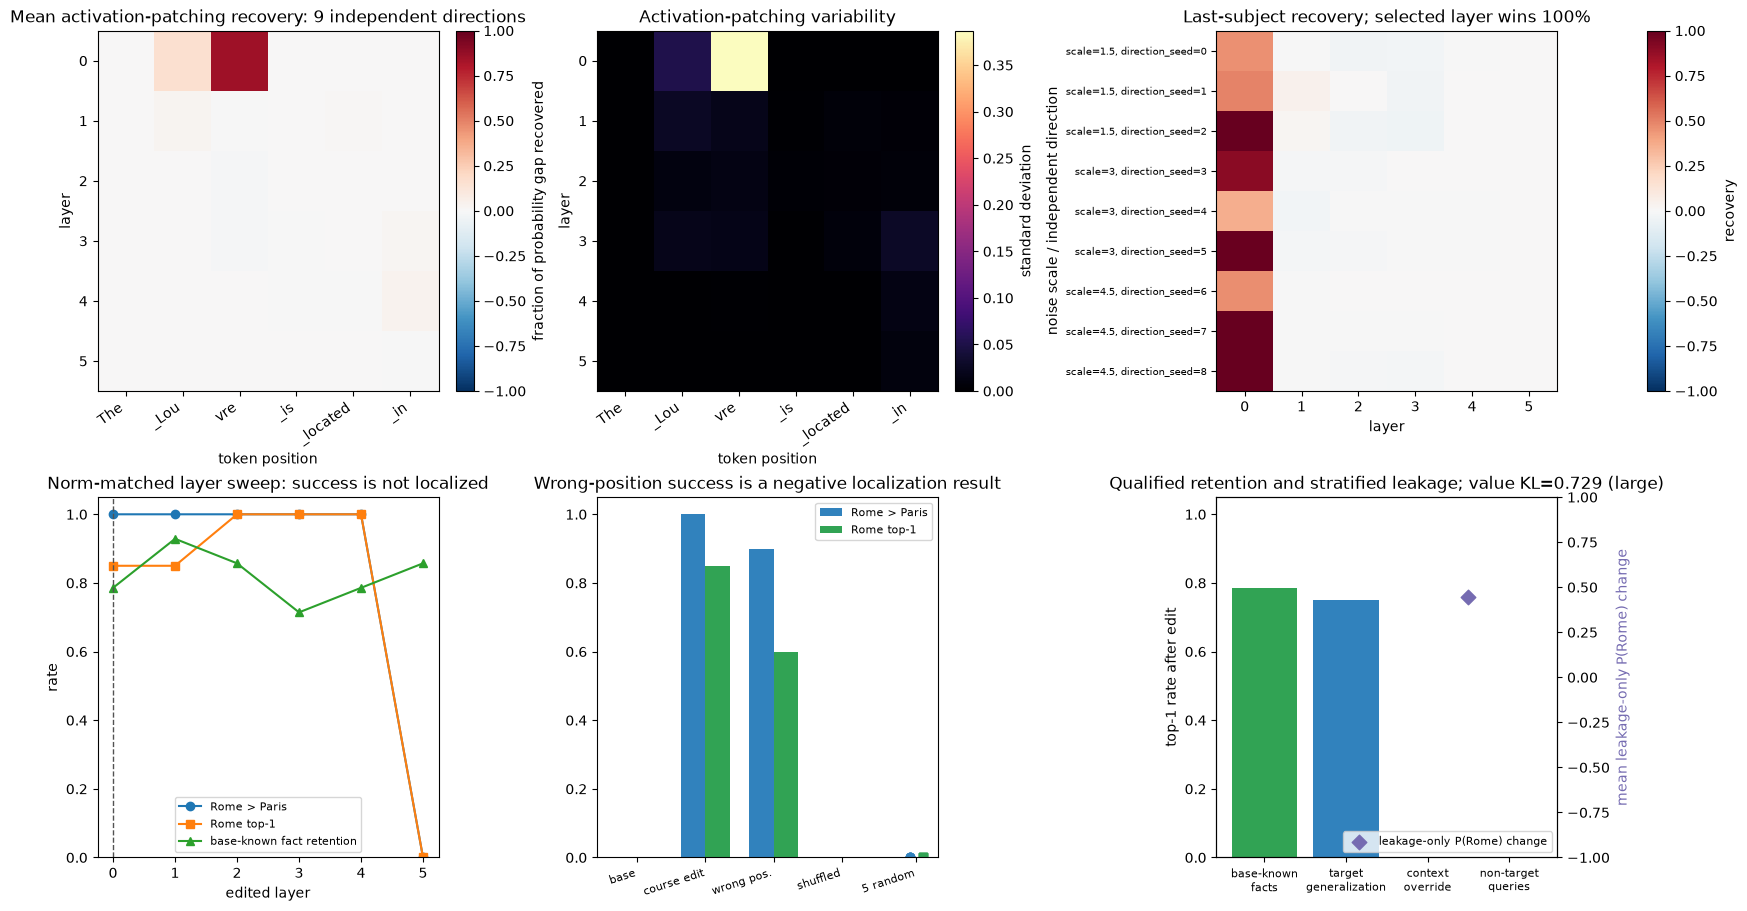

77894

In [30]:
learner_functions = LearnerFunctions(
    activation_patching_sweep=activation_patching_sweep,
    build_update=build_course_rome_like_update,
    evaluate_edit=evaluate_weight_edit,
    rewrite_scorer=score_rewrite_prompts,
    fact_scorer=score_labeled_facts,
    adversarial_scorer=score_adversarial_records,
    metric_summarizer=summarize_edit_metrics,
    random_rank_one=make_same_norm_random_rank_one,
)
tests.check_learner_bundle_uses_notebook_functions(learner_functions)
result = run_course_rome_like_experiment(
    implementation=learner_functions,
    device=device,
    steps=12,
    patching_samples=3,
)
primary_metrics = result["metrics"]["course_rome_like"]
print("NEGATIVE LOCALIZATION RESULT", result["localization_result"])
assert result["localization_result"]["negative_localization_result"]
display(pd.DataFrame(result["layer_sweep"])[[
    "layer",
    "pairwise_preference_rate_after",
    "target_top1_rate_after",
    "mean_full_target_likelihood_after",
    "known_fact_top1_retention_after",
    "side_effect_mean_kl",
    "fluency_perplexity_ratio",
    "native_update_norm",
    "applied_update_norm",
    "native_write_error",
]])
display(pd.DataFrame(result["metrics"]).T[[
    "pairwise_preference_rate_after",
    "target_top1_rate_after",
    "mean_full_target_likelihood_after",
    "known_fact_top1_retention_after",
    "leakage_sensitive_mean_rome_probability_change",
    "side_effect_mean_kl",
    "fluency_perplexity_ratio",
]])
print({
    "selected_layer": result["selected_layer"],
    "condition_best_layers": result["trace"]["condition_best_layers"].tolist(),
    "independent_direction_seeds": result["trace"]["direction_seeds"],
    "layer_0_mean": result["trace"]["layer_zero_mean_recovery"],
    "layer_0_std": result["trace"]["layer_zero_std_recovery"],
    "actual_affine_write_error": result["primary_details"]["write_error"],
    "effective_rank": result["primary_details"]["effective_rank"],
    "value_optimizer_preservation_KL": result["primary_details"]["optimization_history"][-1]["preservation_kl"],
    "value_optimizer_KL_is_large": result["primary_details"]["optimization_history"][-1]["preservation_kl"] > 0.1,
})

paraphrase_table = pd.DataFrame(result["primary_evaluation"]["paraphrase_rows"])
display(paraphrase_table[[
    "prompt_id", "family", "prompt", "base_top_token", "edited_top_token",
    "base_target_rank", "edited_target_rank", "base_new_likelihood",
    "edited_new_likelihood", "pairwise_after", "target_top1_after",
]])
known_fact_table = pd.DataFrame(result["primary_evaluation"]["known_fact_rows"])
display(known_fact_table[known_fact_table["base_qualified_known_fact"]])
adversarial_table = pd.DataFrame(result["primary_evaluation"]["adversarial_rows"])
display(adversarial_table[[
    "prompt_id", "stratum", "counts_as_leakage", "prompt", "label",
    "base_label_rank", "edited_label_rank", "rome_probability_change",
]])
display(pd.DataFrame(result["primary_evaluation"]["generation_rows"]))
print({
    "localized_louvre_repetition_before": primary_metrics["localized_louvre_repetition_before"],
    "localized_louvre_repetition_after": primary_metrics["localized_louvre_repetition_after"],
    "generation_repetition_failure_count": primary_metrics["generation_repetition_failure_count"],
    "scope": "one localized generation failure; not a general fluency conclusion",
    "leakage_only_rome_probability_change": primary_metrics["leakage_sensitive_mean_rome_probability_change"],
})

reference.plot_signature_result(result, str(assets_dir / "rome_model_editing_signature.png"))
plt.show()

summary = reference.serializable_experiment_summary(result)
(section_dir / "expected_outputs" / "reference_metrics.json").write_text(
    json.dumps(summary, indent=2, sort_keys=True) + "\n"
)

<details>
<summary>How to interpret the live result</summary>

1. `pairwise_preference_rate_after` means only that Rome outranks Paris.
2. `target_top1_rate_after` asks whether Rome is the model's actual first choice.
3. `mean_full_target_likelihood_after` scores every target token.
4. Known-fact retention uses only the 14/24 rows answered top-1 before editing; unqualified rows are never a factual-locality denominator.
5. All nine activation-patching conditions use different Gaussian directions.
6. Every layer and wrong-position comparison uses the same update norm. Their broad success is a negative localization result, so no layer is privileged.
7. Leakage excludes `target_generalization` and `legitimate_rome_target` rows by construction.
8. The value optimizer's preservation KL exceeds the 0.1 warning threshold and is reported as large.
9. Repetition increased on one Louvre generation. That is one localized generation failure, not evidence of general fluency loss.

</details>

## Try It Yourself

This is a **scoring-only** play cell for the already-built fixed Louvre-to-Rome edit.
Changing `target` changes only what the scorer measures. It does not optimize a new value,
alter the fixed edit, or implement a multi-token edit.

,scale,fixed_edit,scored_target_only,target_token_count,full_target_likelihood,first_target_rank,full_target_greedy_match
0,0.0,Louvre -> Rome,Rome,1,0.004396,16,False
1,0.5,Louvre -> Rome,Rome,1,0.995145,1,True
2,1.0,Louvre -> Rome,Rome,1,0.992766,1,True
3,1.5,Louvre -> Rome,Rome,1,0.988259,1,True


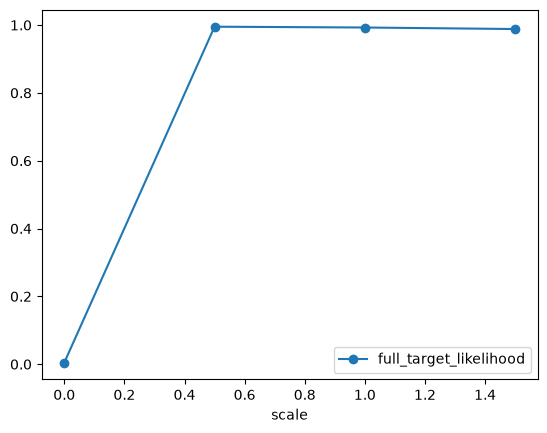

,scale,fixed_edit,scored_target_only,target_token_count,full_target_likelihood,first_target_rank,full_target_greedy_match
0,0.0,Louvre -> Rome,New York,2,0.003653,17,False
1,1.0,Louvre -> Rome,New York,2,0.005980,9,False


In [31]:
def score_fixed_louvre_edit(
    prompt: str,
    target: str = NEW_OBJECT,
    scales: Sequence[float] = (0.0, 0.5, 1.0, 1.5),
) -> pd.DataFrame:
    rows = []
    for scale in scales:
        with temporary_mlp_weight_edit(
            model,
            result["selected_layer"],
            result["primary_update"] * scale,
        ):
            scored = continuation_score_table(model, tokenizer, [prompt], [target])
        rows.append({
            "scale": scale,
            "fixed_edit": "Louvre -> Rome",
            "scored_target_only": target,
            "target_token_count": int(scored["target_token_counts"][0]),
            "full_target_likelihood": float(scored["target_likelihoods"][0]),
            "first_target_rank": int(scored["first_target_ranks"][0]),
            "full_target_greedy_match": bool(scored["full_target_greedy_matches"][0]),
        })
    return pd.DataFrame(rows)


play = score_fixed_louvre_edit("A first-time visitor can see the Louvre in")
display(play)
play.plot(x="scale", y="full_target_likelihood", marker="o")
plt.show()

# Scoring-only multi-token diagnostic: this still applies the fixed Louvre -> Rome matrix.
# It does not train or claim a New York edit.
display(score_fixed_louvre_edit("Times Square is in", target=" New York", scales=(0.0, 1.0)))

## Further research / anomaly hunting

- Add more harmless counterfactuals and report a distribution, not another anecdote.
- Establish official parity separately with Wikipedia-derived covariance, random-prefix contexts,
  and the released value objective before using an unqualified ROME label.
- Increase activation-patching samples and test other corruption families.
- Expand the predeclared candidate pool before qualifying base-known facts.
- Repeat edits sequentially and measure whether earlier edits and broad language metrics survive.
- Test whether the negative localization result persists across models and facts.

## Limitations

This notebook uses one harmless counterfactual, one small pretrained decoder, 24 covariance
contexts, 20 held-out paraphrases, 24 known-fact candidates, 16 stratified adversarial contexts,
and short course-authored perplexity probes. Only base-top-1 candidate facts enter the retention
denominator. Activation patching is not protocol-parity causal tracing. The course edit omits
Wikipedia covariance, random-prefix contexts, and released value-objective parity. Its large
optimizer KL, broad norm-matched layer success, wrong-position success, and one repetitive Louvre
continuation are negative evidence. The repetition example is not a general fluency claim. The lab
does not establish durable knowledge change, unique factual storage, repeated-edit safety, or
benchmark-level ROME performance.

## Reading

- Meng et al., *Locating and Editing Factual Associations in GPT* and the official ROME code.
- Hase et al., *Does Localization Inform Editing?*
- The original ARENA Function Vectors and Model Steering section for intervention pedagogy.

In [32]:
tests.test_smoke_contract_is_exact(reference.run_smoke_test)
tests.test_model_and_revision_are_pinned()
tests.test_section_local_release_report_generation_inputs_are_strict()
tests.test_notebook_contract()

All tests in `test_smoke_contract_is_exact` passed!
All tests in `test_model_and_revision_are_pinned` passed!
All tests in `test_section_local_release_report_generation_inputs_are_strict` passed!
All tests in `test_notebook_contract` passed!
